# $\nu_e$ CC Inclusive — event analysis

In [1]:
%matplotlib inline
import os, sys, gc, re, json, warnings, datetime, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LogNorm
 
CAFPYANA_WD = '/home/castalyf/cafpyana'
for p in [CAFPYANA_WD, CAFPYANA_WD + '/pyanalib', CAFPYANA_WD + '/analysis_village/nueCC']:
    if p not in sys.path:
        sys.path.insert(0, p)
 
# ── What to run ───────────────────────────────────────────────────────────────
RUN_EXPORT   = True    # Part A: ntuples → saved_csvs/ (slow, ~13 GB RSS). False = Part B only.
EXPORT_DATA  = True    # on-beam data rows: Gen1 dev sample only. Keep False for Gen2 until a stage is approved.
DATA_POT_CAP = 1.0e19  # export refuses on-beam data above this POT (open/dev-sample size)
INSPECT      = True    # print the reco/true column names once (to extend the export later)
 
# ── Inputs (same as the data/MC notebook) ─────────────────────────────────────
PRODUCTION = 'gen1_v2'
PROD       = f'/exp/sbnd/data/users/castalyf/nue_sel/production_files/{PRODUCTION}'
DF_OUT_DIR = './nuecc_dfs'
SEL_FILE     = f'{DF_OUT_DIR}/selected_nuecc_qual.df'
PROD_MC    = '/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610'   # remade MC (must match nue_selection.ipynb)
DF_FILE      = f'{PROD_MC}/mc1e20_nueCC_2610.df'
LOWE_FILE    = f'{PROD_MC}/mc1e20_lowE_2610.df'
INTIME_FILE  = f'{PROD_MC}/mc_intime_cosmic_2610.df'
DATA_FILE    = f'{PROD_MC}/data_dev_2610.df'
OFFBEAM_FILE = f'{PROD_MC}/data_offbeamlight_2610.df'   # same events as gen1_v2, remade file
TARGET_POT = 6.6e20
KE_MIN     = 500.0     # MeV — leading-shower threshold for exported rows and for data blinding
 
CSV_DIR  = './saved_csvs'
PLOT_DIR = './plots_analysis'
for d in (CSV_DIR, PLOT_DIR):
    os.makedirs(d, exist_ok=True)
 
def savefig(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f'{name}.png'), dpi=150, bbox_inches='tight')
    display(fig)
    plt.close(fig)
# Plot style shared with nue_plotter.py (nue_syst / nue_selection): data/MC stack + ratio panel
# = (8, 7.5) per panel, MC-only stack = (8, 6) per panel, legend font 10.
DATAMC_FIGSIZE, STACK_FIGSIZE, DATAMC_LEGEND_FS, DATAMC_HEADROOM = (8, 7.5), (8, 6), 10, 1.6


def headroom(ax, factor=DATAMC_HEADROOM):
    """Room above the stack for the legend (linear: × factor; log: the decade range × factor)."""
    lo, hi = ax.get_ylim()
    if ax.get_yscale() == 'log':
        ax.set_ylim(lo, lo * (hi / lo) ** factor)
    else:
        ax.set_ylim(0, hi * factor)


print('config OK')


config OK


## Part 1 — export loaded events to CSV
### 1.1 Export helpers

In [2]:
PID_NAMES = {0: 'photon', 1: 'electron', 2: 'muon', 3: 'pion', 4: 'proton'}
 
# leading-particle fields: output name → (field, sub-field); missing fields are skipped
SHOWER_FIELDS = {
    'id': ('id', ''), 'calo_ke': ('calo_ke', ''), 'ke': ('ke', ''), 'pid': ('pid', ''),
    'start_dedx': ('start_dedx', ''), 'vertex_distance': ('vertex_distance', ''),
    'length': ('length', ''), 'is_primary': ('is_primary', ''), 'is_contained': ('is_contained', ''),
    'primary_score': ('primary_scores', 'I1'),
    'pid_score_photon': ('pid_scores', 'I0'), 'pid_score_electron': ('pid_scores', 'I1'),
    'pid_score_muon': ('pid_scores', 'I2'), 'pid_score_pion': ('pid_scores', 'I3'),
    'pid_score_proton': ('pid_scores', 'I4'),
}
TRACK_FIELDS = {
    'id': ('id', ''), 'pid': ('pid', ''), 'length': ('length', ''), 'ke': ('ke', ''), 'calo_ke': ('calo_ke', ''),
    'csda_ke': ('csda_ke', ''), 'is_contained': ('is_contained', ''), 'is_primary': ('is_primary', ''),
}
# interaction-level fields (first sub-column of each, if present)
INTER_FIELDS = ['id', 'is_contained', 'is_fiducial', 'flash_total_pe', 'flash_times', 'flash_scores',
                'flash_hypo_pe', 'nu_score', 'topology']
 
 
def _col(df, field, sub=''):
    cols = df.columns
    for c in ((field, sub), field):
        if c in cols:
            return c
    for c in cols:
        if isinstance(c, tuple) and c and c[0] == field and (sub == '' or sub in c[1:]):
            return c
    return None
 
 
def _dir_cols(df):
    return [next((c for c in df.columns if 'start_dir' in str(c) and k in str(c)), None)
            for k in ('I0', 'I1', 'I2')]
 
 
def _leading(rp, inter_idx, il, pids, prefix, fields, key='calo_ke'):
    # Leading particle (max `key`) among `pids` per interaction in inter_idx.
    pidc = _col(rp, 'pid')
    keyc = _col(rp, key) or _col(rp, 'ke')
    m = np.asarray(rp.index.droplevel(-1).isin(inter_idx)) & rp[pidc].isin(list(pids)).to_numpy()
    sub = rp.loc[m]
    if sub.empty:
        return pd.DataFrame()
    lead = sub[keyc].astype(float).fillna(-np.inf).groupby(level=il).idxmax()
    ld = sub.loc[pd.MultiIndex.from_tuples(lead.values, names=sub.index.names)]
    out = pd.DataFrame(index=lead.index)
    for name, (f, s) in fields.items():
        c = _col(rp, f, s)
        if c is not None:
            out[prefix + name] = pd.to_numeric(ld[c], errors='coerce').to_numpy(dtype=float)
    d = _dir_cols(rp)
    if all(c is not None for c in d):
        v = ld[d].to_numpy(dtype=float)
        n = np.linalg.norm(v, axis=1)
        n[n == 0] = np.nan
        out[prefix + 'costheta'] = v[:, 2] / n
    return out
 
 
def _mult(rp, inter_idx, il):
    pidc, primc = _col(rp, 'pid'), _col(rp, 'is_primary')
    sub = rp.loc[np.asarray(rp.index.droplevel(-1).isin(inter_idx))]
    pid = sub[pidc]
    out = {}
    for k, n in PID_NAMES.items():
        out[f'n_{n}'] = (pid == k).groupby(level=il).sum()
        if primc is not None:
            out[f'n_{n}_primary'] = ((pid == k) & sub[primc].astype(bool)).groupby(level=il).sum()
    return pd.DataFrame(out)
 
 
def _inter(evtdf, inter_idx, il):
    ri = evtdf['rec']['dlp']
    cols = {}
    for coord, alt in zip('xyz', ('I0', 'I1', 'I2')):
        c = next((cc for cc in [('vertex', coord, ''), ('vertex', coord), ('vertex', alt, ''), ('vertex', alt)]
                  if cc in ri.columns), None)
        if c is not None:
            cols[f'vtx_{coord}'] = c
    for f in INTER_FIELDS:
        c = next((cc for cc in ri.columns if isinstance(cc, tuple) and cc[0] == f), None)
        if c is not None:
            cols[f'int_{f}'] = c
    if not cols:
        return pd.DataFrame()
    sel = ri.loc[np.asarray(ri.index.droplevel(-1).isin(inter_idx)), list(cols.values())]
    g = sel.groupby(level=il).first()
    g.columns = list(cols.keys())
    return g.apply(pd.to_numeric, errors='coerce')
 
 
def _hdr_all(path):
    with pd.HDFStore(path, mode='r') as st:
        keys = sorted((k for k in st.keys() if re.match(r'^/hdr_\d+$', k)),
                      key=lambda k: int(k.rsplit('_', 1)[1]))
        return pd.concat([st[k] for k in keys]) if keys else None
 
 
def _rse(path, inter_index):
    # run/subrun/evt per interaction via hdr keys (index levels 0,1 = __ntuple, entry).
    h = _hdr_all(path)
    if h is None:
        return None
    ev = 'evt' if 'evt' in h.columns else 'event'
    extra = [c for c in ('fno', 'proc', 'cluster') if c in h.columns]
    r = h[['run', 'subrun', ev] + extra].groupby(level=[0, 1]).first()
    r.columns = ['run', 'subrun', 'evt'] + [f'hdr_{c}' for c in extra]
    k = pd.MultiIndex.from_arrays([inter_index.get_level_values(0), inter_index.get_level_values(1)])
    return r.reindex(k)
 
 
def _flags_from_cutflow(cut_flow):
    fv = cut_flow['fiducial']['inter_index']
    return pd.DataFrame({f'sel_{s}': fv.isin(d['inter_index']) for s, d in cut_flow.items()}, index=fv)
 
 
# identification / bookkeeping columns, always written first (left-most) in every CSV
META_COLS = ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2',
             'int_id', 'sh_id', 'e_id', 'trk_id', 'hdr_fno', 'hdr_proc', 'hdr_cluster', 'w_data', 'w_target']
 
 
def order_columns(df):
    df = df.copy()
    for c in ('run', 'subrun', 'evt'):
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce').astype('Int64')
    first = [c for c in META_COLS if c in df.columns]
    return df[first + [c for c in df.columns if c not in first]]
 
 
def _put(t, sub):
    # Copy columns of `sub` into `t`, aligned on the interaction index.
    if sub is None or len(sub) == 0:
        return
    sub = sub.copy()
    sub.index = sub.index.set_names(t.index.names)
    sub = sub[~sub.index.duplicated(keep='first')].reindex(t.index)
    for c in sub.columns:
        t[str(c)] = sub[c].to_numpy()
 
 
def _selection_electron(evtdf, inter_idx):
    # lp_*: the particle the selection cuts on — leading PRIMARY reco electron with KE > 500 MeV
    # (nue_selection.leading_primary_electron, the same one shower_qual_cuts uses)
    import nue_selection as _ns
    lp = _ns.leading_primary_electron(evtdf)
    lp = lp[lp.index.isin(inter_idx)]
    out = pd.DataFrame(index=lp.index)
    for name, (f, s) in SHOWER_FIELDS.items():
        c = _col(lp, f, s)
        if c is not None:
            out['lp_' + name] = pd.to_numeric(lp[c], errors='coerce').to_numpy(dtype=float)
    return out


def build_table(evtdf, flags, sample, path, w_data, w_target, extra=None, blind_data=False,
                truth_cat=None):
    il = list(range(evtdf.index.nlevels - 1))
    names = [f'idx{i}' for i in range(len(il))]
    rp = evtdf['rec']['dlp']['particles']
    flags = flags.copy()
    flags.index = flags.index.set_names(names)
    fv = flags.index[flags['sel_fiducial'].to_numpy(dtype=bool)]
 
    sh = _leading(rp, fv, il, (0, 1), 'sh_', SHOWER_FIELDS)
    sh.index = sh.index.set_names(names)
    keep = sh.index[(sh['sh_calo_ke'] >= KE_MIN).to_numpy()]
    if 'sel_single_electron' in flags and not blind_data:
        keep = keep.union(flags.index[flags['sel_single_electron'].to_numpy(dtype=bool)])
    keep = keep.set_names(names)
 
    t = pd.DataFrame(index=keep)
    _put(t, flags)
    for c in flags.columns:
        t[c] = pd.Series(t[c]).fillna(False).astype(bool).to_numpy()
    _put(t, sh)
    _put(t, _leading(rp, keep, il, (1,), 'e_', SHOWER_FIELDS))
    _put(t, _selection_electron(evtdf, keep))
    _put(t, _leading(rp, keep, il, (2, 3, 4), 'trk_', TRACK_FIELDS, key='length'))
    m = _mult(rp, keep, il)
    _put(t, m)
    for c in m.columns:
        t[c] = pd.Series(t[c]).fillna(0).astype(int).to_numpy()
    _put(t, _inter(evtdf, keep, il))
    try:
        r = _rse(path, keep)
        if r is not None:
            for c in r.columns:
                t[c] = r[c].to_numpy()
    except Exception as e:
        print(f'  [{sample}] run/subrun/evt not added: {e}')
    if extra is not None:
        _put(t, extra)
    if truth_cat is not None:
        t['truth_cat'] = truth_cat
    t['sample'], t['w_data'], t['w_target'] = sample, w_data, w_target
    if blind_data:
        n0 = len(t)
        t = t[t['sh_calo_ke'] >= KE_MIN]
        print(f'  [{sample}] blinding: kept {len(t):,}/{n0:,} rows with sh_calo_ke ≥ {KE_MIN:g} MeV')
    print(f'  [{sample}] {len(t):,} rows × {t.shape[1]} cols')
    return order_columns(t.reset_index())
 
 
CF_ROWS = []
def add_cutflow_flags(sample, sel, w_data, w_target):
    # MC-like samples: counts per stage and truth_cat from a sel_* flag frame.
    for c in [c for c in sel.columns if c.startswith('sel_')]:
        for cat, n in sel.groupby('truth_cat')[c].sum().items():
            CF_ROWS.append(dict(sample=sample, stage=c[4:], truth_cat=int(cat), n_raw=int(n),
                                n_w_data=n * w_data, n_w_target=n * w_target))
 
def add_cutflow_dict(sample, cut_flow, w_data, w_target, truth_cat):
    for s, d in cut_flow.items():
        n = len(d['inter_index'])
        CF_ROWS.append(dict(sample=sample, stage=s, truth_cat=truth_cat, n_raw=n,
                            n_w_data=n * w_data, n_w_target=n * w_target))
 
 
def inspect_columns(evtdf):
    rp, ri = evtdf['rec']['dlp']['particles'], evtdf['rec']['dlp']
    fields = lambda df: sorted({c[0] if isinstance(c, tuple) else c for c in df.columns})
    print('index levels :', evtdf.index.names)
    print('reco particle fields :', fields(rp))
    print('reco interaction fields:', [f for f in fields(ri) if f != 'particles'])
    if 'dlp_true' in evtdf['rec'].columns.get_level_values(0):
        print('true particle fields (kept):', fields(evtdf['rec']['dlp_true']['particles']))
    print('match-like reco columns:', [c for c in rp.columns if 'match' in str(c)][:10])
print('helpers OK')


helpers OK


## 1.2 Load selection, POT and normalizations

In [3]:
if RUN_EXPORT:
    import nue_helpers as nh
    import nue_selection as nue_sel
    from mem_optimizer import load_evtdf_slim
 
    CUT_NAMES   = list(nue_sel.CUT_NAMES_MORE)
    FINAL_STAGE = f'sel_{CUT_NAMES[-1]}'
 
    st = nh.load_sel_topo(SEL_FILE, df_file=DF_FILE)
    sel_topo, pot_scale, statsdf = st['sel_topo'], st['pot_scale'], st['statsdf']
    mc_sample_pot = TARGET_POT / pot_scale
 
    with pd.HDFStore(DATA_FILE, mode='r') as s:
        data_pot = float(s['pot_0']['TOR860'].sum())
    pot_scale_to_data = data_pot / mc_sample_pot
 
    lt = nh.livetime_scales(DATA_FILE, OFFBEAM_FILE, INTIME_FILE)
    offbeam_scale, intime_scale = lt['offbeam_scale'], lt['intime_scale']
    offbeam_scale_t = offbeam_scale * TARGET_POT / data_pot
    intime_scale_t  = intime_scale  * TARGET_POT / data_pot
 
    if EXPORT_DATA and data_pot > DATA_POT_CAP:
        raise RuntimeError(f'Data POT {data_pot:.2e} > DATA_POT_CAP {DATA_POT_CAP:.1e}: '
                           'not an open sample — set EXPORT_DATA=False or get approval first.')
    print(f'FINAL_STAGE={FINAL_STAGE}  MC POT={mc_sample_pot:.3e}  data POT={data_pot:.3e}')
    print(f'offbeam_scale={offbeam_scale:.6f}  intime_scale={intime_scale:.4e}')


sel_topo shape : (3626750, 19)
pot_scale      : 1.1734
n_true_signal  : 11,560
  sel_precut                          sig=11,159  total=3,626,750
  sel_valid_flashmatch                sig=11,159  total=3,626,750
  sel_fiducial                        sig=11,159  total=3,626,750
  sel_single_electron                 sig=10,136  total=   23,829
  sel_electron_primary_score          sig= 9,771  total=   21,628
  sel_electron_pid_score              sig= 8,450  total=   13,139
  sel_vertex_distance                 sig= 7,795  total=   10,803
  sel_start_dedx                      sig= 4,634  total=    5,164
On-beam BNB gates (pot_0, TOR860>0): 927,556  (4.83e+12 POT/spill)
Trigger rate per gate: on-beam 88,046/927,556 = 9.4923%   off-beam 1,660,552/83,691,835 = 1.9841%
ν-triggered gate fraction f = (R_on − R_off)/(1 − R_off) = 0.0766 (data)   fixed value 0.0725   → using f = 0.0766
Off-beam gates (noffbeambnb):     83,691,835  → offbeam_scale = 0.010234  (0.9956 × the fixed-f value)
In-time ge

## 1.3 Main MC (BNB + cosmics)

In [4]:
if RUN_EXPORT:
    mc_evtdf = load_evtdf_slim(DF_FILE, key=None, mode='reco_min_true')
    if INSPECT:
        inspect_columns(mc_evtdf)
 
    sel_cols = [c for c in sel_topo.columns if c.startswith('sel_')]
    keep_truth = [c for c in ['truth_cat', 'is_sig', 'true_ke', 'true_costheta', 'true_p',
                              'reco_ke', 'reco_costheta', 'reco_p'] if c in sel_topo.columns]
    extra = sel_topo[keep_truth].rename(columns={c: f'ana_{c}' for c in keep_truth if c.startswith('reco_')})
 
    # truth_info (all numeric columns, prefixed ti_) — e.g. interaction mode, true Eν if stored
    ti = statsdf.select_dtypes(include=[np.number, bool])
    ti = ti[[c for c in ti.columns if c != 'truth_cat']]
    ti.columns = [f"ti_{'_'.join(str(p) for p in c if str(p)) if isinstance(c, tuple) else c}" for c in ti.columns]
    if ti.index.nlevels == extra.index.nlevels:
        ti.index = ti.index.set_names(extra.index.names)
        ti = ti[~ti.index.duplicated(keep='first')]
        extra = extra.join(ti, how='left')
    else:
        print(f'truth_info index has {ti.index.nlevels} levels (selection: {extra.index.nlevels}) — ti_ columns skipped')
 
    mc_tab = build_table(mc_evtdf, sel_topo[sel_cols], 'mc', DF_FILE,
                         pot_scale_to_data, pot_scale, extra=extra)
    # every preselected interaction must exist in DF_FILE — otherwise SEL_FILE was made from another MC file
    _miss = mc_tab.loc[mc_tab['sel_fiducial'], 'vtx_x'].isna().mean() if 'vtx_x' in mc_tab else 0.0
    if _miss > 0.01:
        raise RuntimeError(f'{100*_miss:.0f}% of preselected interactions not found in DF_FILE — SEL_FILE was '
                           'made from a different MC file (check DF_FILE vs MERGED_FILE in nue_selection.ipynb)')
    mc_tab.to_csv(f'{CSV_DIR}/events_mc.csv', index=False)
    add_cutflow_flags('mc', sel_topo[sel_cols + ['truth_cat']], pot_scale_to_data, pot_scale)
 
    N_SIG_PRESEL = int(sel_topo['is_sig'].sum())
    # one row per true signal ν (truth_cat==0 would count split ν twice and miss unreconstructed ones)
    N_SIG_TRUTH  = (int(statsdf['is_true_signal'].sum()) if 'is_true_signal' in statsdf.columns
                    else int((statsdf['truth_cat'] == 0).sum()) if 'truth_cat' in statsdf.columns else None)
    del mc_evtdf, extra, ti
    gc.collect()



load_evtdf_slim  mode='reco_min_true'  keys=4/4 downcast=True
  columns from '/evt_0':
  Total cols :  393  →  kept:   94  dropped:  299  (76% reduced)
  Group                            all   kept
  ------------------------------------------
  dlp_reco_interaction              32     20  ← dropped 12
  dlp_reco_particle                 72     54  ← dropped 18
  dlp_true_interaction              68      0  ← dropped 68
  dlp_true_particle                113     16  ← dropped 97
  mcnu                             104      0  ← dropped 104
  index_artifact                     4      4
  other                              0      0

  [ 1/4] /evt_0   rows=4,252,904  cum=  4,252,904  RSS=5.34 GB
  [ 2/4] /evt_1   rows=4,250,248  cum=  8,503,152  RSS=6.73 GB
  [ 3/4] /evt_2   rows=4,237,837  cum= 12,740,989  RSS=8.14 GB
  [ 4/4] /evt_3   rows=4,241,374  cum= 16,982,363  RSS=9.57 GB
  Concatenating 4 parts (16,982,363 rows) ...
  Final shape: (16982363, 94)  (~5.80 GB)
  [after evtdf load] R

/tmp/ipykernel_117406/3628219282.py:141: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  t[str(c)] = sub[c].to_numpy()
/tmp/ipykernel_117406/3628219282.py:141: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  t[str(c)] = sub[c].to_numpy()
/tmp/ipykernel_117406/3628219282.py:141: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newfram

  [mc] 55,246 rows × 115 cols


## 1.4 Low-energy dirt

In [5]:
if RUN_EXPORT:
    lowE = nh.load_lowE_sample(LOWE_FILE, TARGET_POT, data_pot)
    lsel = lowE['sel']
    lsel_cols = [c for c in lsel.columns if c.startswith('sel_')]
    lextra = lsel[['truth_cat', 'is_sig', 'reco_ke', 'reco_costheta', 'reco_p']].rename(
        columns={'reco_ke': 'ana_reco_ke', 'reco_costheta': 'ana_reco_costheta', 'reco_p': 'ana_reco_p'})
    dirt_tab = build_table(lowE['evtdf'], lsel[lsel_cols], 'dirt', LOWE_FILE,
                           lowE['pot_scale_to_data'], lowE['pot_scale'], extra=lextra)
    dirt_tab.to_csv(f'{CSV_DIR}/events_dirt.csv', index=False)
    add_cutflow_flags('dirt', lsel[lsel_cols + ['truth_cat']], lowE['pot_scale_to_data'], lowE['pot_scale'])
    LOWE_POT_SCALES = (lowE['pot_scale_to_data'], lowE['pot_scale'])
    del lowE, lsel, lextra
    gc.collect()



load_evtdf_slim  mode='reco_min_true'  keys=5/5 downcast=True
  columns from '/evt_0':
  Total cols :  393  →  kept:   94  dropped:  299  (76% reduced)
  Group                            all   kept
  ------------------------------------------
  dlp_reco_interaction              32     20  ← dropped 12
  dlp_reco_particle                 72     54  ← dropped 18
  dlp_true_interaction              68      0  ← dropped 68
  dlp_true_particle                113     16  ← dropped 97
  mcnu                             104      0  ← dropped 104
  index_artifact                     4      4
  other                              0      0

  [ 1/5] /evt_0   rows=  190,498  cum=    190,498  RSS=7.16 GB
  [ 2/5] /evt_1   rows=  190,051  cum=    380,549  RSS=7.16 GB
  [ 3/5] /evt_2   rows=  189,190  cum=    569,739  RSS=7.16 GB
  [ 4/5] /evt_3   rows=  187,721  cum=    757,460  RSS=7.16 GB
  [ 5/5] /evt_4   rows=  100,528  cum=    857,988  RSS=7.16 GB
  Concatenating 5 parts (857,988 rows) ...
  Fi

Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

LowE: dropped 292,647 cosmic interactions (predicted by off-beam + main MC)
  precut                        :   89,945
  valid_flashmatch              :   89,945
  fiducial                      :   89,945
  single_electron               :       13
  electron_primary_score        :       13
  electron_pid_score            :        3
  vertex_distance               :        1
  start_dedx                    :        0
  [dirt] 14 rows × 85 cols


## 1.5 Off-beam data and in-time cosmic MC

In [6]:
if RUN_EXPORT:
    for sample, path, w_d, w_t, tcat in [('offbeam', OFFBEAM_FILE, offbeam_scale, offbeam_scale_t, 8),
                                         ('intime',  INTIME_FILE,  intime_scale,  intime_scale_t, 10)]:
        evt, _ = nh.patch_vertex_cols(pd.read_hdf(path, key='evt_0'))
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            cf = nue_sel.shower_qual_cuts(evt)
        tab = build_table(evt, _flags_from_cutflow(cf), sample, path, w_d, w_t, truth_cat=tcat)
        tab.to_csv(f'{CSV_DIR}/events_{sample}.csv', index=False)
        add_cutflow_dict(sample, cf, w_d, w_t, tcat)
        del evt, cf, tab
        gc.collect()


Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

  [offbeam] 3,636 rows × 92 cols


Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

  [intime] 3,574 rows × 92 cols


## 1.6 On-beam data (dev sample only, blinded below KE_MIN)

In [7]:
if RUN_EXPORT and EXPORT_DATA:
    data = nh.load_onbeam_data(DATA_FILE, TARGET_POT, pot_scale)
    data_tab = build_table(data['evtdf'], _flags_from_cutflow(data['cut_flow']), 'data', DATA_FILE,
                           1.0, np.nan, blind_data=True, truth_cat=-1)
    data_tab.to_csv(f'{CSV_DIR}/events_data.csv', index=False)
    add_cutflow_dict('data', data['cut_flow'], 1.0, np.nan, -1)
 
    # POT per run (for ≤1e19-per-plot time slicing)
    h = _hdr_all(DATA_FILE)
    if h is not None and {'pot', 'run'} <= set(h.columns):
        first = h['first_in_subrun'].astype(bool) if 'first_in_subrun' in h else ~h.duplicated(['run', 'subrun'])
        pbr = h[first].groupby('run')['pot'].sum().rename('pot').reset_index()
        pbr.to_csv(f'{CSV_DIR}/data_pot_by_run.csv', index=False)
        print(f'POT by run: {len(pbr)} runs, Σ={pbr.pot.sum():.3e} (TOR860 total {data_pot:.3e})')
    del data
    gc.collect()
elif RUN_EXPORT:
    for f in ('events_data.csv', 'data_pot_by_run.csv'):
        if os.path.exists(f'{CSV_DIR}/{f}'):
            os.remove(f'{CSV_DIR}/{f}')
            print(f'removed stale {f} (EXPORT_DATA=False)')


Data: (156521, 100)  POT=4.476e+18  pot_scale_to_data=0.0080  renamed 3 vertex cols


Building cut flow:   0%|          | 0/4 [00:00<?, ?it/s]

Shower quality cuts:   0%|          | 0/4 [00:00<?, ?it/s]

Data cut flow:
  precut                        :   39,225
  valid_flashmatch              :   39,225
  fiducial                      :   39,225
  single_electron               :      206
  electron_primary_score        :      190
  electron_pid_score            :      114
  vertex_distance               :       91
  start_dedx                    :       35
  [data] blinding: kept 412/412 rows with sh_calo_ke ≥ 500 MeV
  [data] 412 rows × 92 cols
POT by run: 2 runs, Σ=4.518e+18 (TOR860 total 4.476e+18)


## 1.7 Cut flow + metadata

In [8]:
COLUMN_DOC = {
    'idx0, idx1, idx2': 'interaction index (__ntuple, entry, rec.dlp index) — joins back to the HDF5 files',
    'run, subrun, evt': 'from hdr_* keys (use these to find the event in the SPINE HDF5 files / spinal-tap)',
    'int_id, sh_id, e_id, trk_id': 'SPINE reco interaction id and particle ids (what spinal-tap displays)',
    'hdr_fno, hdr_proc, hdr_cluster': 'grid-job bookkeeping from hdr, if present',
    'sample': 'mc | dirt | offbeam | intime | data',
    'w_data': 'weight to the on-beam data POT of DATA_FILE (data rows = 1)',
    'w_target': 'weight to TARGET_POT (off-beam/in-time scaled by TARGET_POT/data POT)',
    'truth_cat': '0 νe CC FV, 1 νe CC out-FV, 2 νμ CC π0, 3 NC π0, 4 other νμ CC, 5 other NC, 6 other ν, '
                 '7 cosmic (MC); 8 off-beam, 10 in-time MC, -1 data',
    'is_sig': 'true signal (truth_cat 0)',
    'sel_<stage>': 'passes the cumulative selection stage <stage> (nue_selection.shower_qual_cuts)',
    'sh_*': 'leading e/γ shower (SPINE PID 0 or 1, max calo_ke)',
    'e_*': 'leading SPINE-electron (PID 1, max calo_ke; any primary flag / KE)',
    'lp_*': 'leading PRIMARY SPINE-electron with KE > 500 MeV — the particle the selection cuts on',
    'trk_*': 'longest track (PID 2,3,4)',
    'n_<pid>[_primary]': 'reco particle multiplicities',
    'vtx_x/y/z, int_*': 'reco interaction vertex and interaction-level fields',
    'ana_reco_ke/costheta/p': 'leading-electron kinematics as stored in the selection df',
    'true_ke/costheta/p': 'true electron kinematics (signal)',
    'ti_*': 'numeric truth_info columns',
}
 
if RUN_EXPORT:
    if CF_ROWS:
       pd.DataFrame(CF_ROWS).to_csv(f'{CSV_DIR}/cutflow.csv', index=False)
    else:
       print('CF_ROWS is empty (A.3–A.6 not run in this session) → cutflow.csv left untouched')
    try:
        git = subprocess.run(['git', '-C', CAFPYANA_WD, 'rev-parse', '--short', 'HEAD'],
                             capture_output=True, text=True).stdout.strip()
    except Exception:
        git = ''
    thr = {k: getattr(nue_sel, k) for k in dir(nue_sel)
           if k.isupper() and isinstance(getattr(nue_sel, k), (int, float, str, list, tuple))}
    meta = dict(
        created=datetime.datetime.now().isoformat(timespec='seconds'), production=PRODUCTION,
        cafpyana_git=git, files=dict(sel=SEL_FILE, mc=DF_FILE, dirt=LOWE_FILE, intime=INTIME_FILE,
                                     data=DATA_FILE, offbeam=OFFBEAM_FILE),
        target_pot=TARGET_POT, data_pot=data_pot, mc_sample_pot=mc_sample_pot,
        scales=dict(mc_to_target=pot_scale, mc_to_data=pot_scale_to_data,
                    dirt_to_data=LOWE_POT_SCALES[0], dirt_to_target=LOWE_POT_SCALES[1],
                    offbeam_to_data=offbeam_scale, offbeam_to_target=offbeam_scale_t,
                    intime_to_data=intime_scale, intime_to_target=intime_scale_t,
                    beam_duty_fraction=lt['f_used'], beam_duty_fraction_data=lt['f_data'],
                    trig_rate_on=lt['trig_rate_on'], trig_rate_off=lt['trig_rate_off']),
        livetime=dict(onbeam_spills=lt['onbeam_nspills'], offbeam_gates=lt['offbeam_ngates'],
                      intime_ngenevt=lt['intime_ngenevt']),
        ke_min_mev=KE_MIN, final_stage=FINAL_STAGE, cut_names=CUT_NAMES, thresholds=thr,
        n_sig_presel=N_SIG_PRESEL, n_sig_truth_info=N_SIG_TRUTH,
        data_exported=bool(EXPORT_DATA), data_blinded_below_mev=KE_MIN,
        csv_files=sorted(f for f in os.listdir(CSV_DIR) if f.endswith('.csv')),
        columns=COLUMN_DOC)
    with open(f'{CSV_DIR}/metadata.json', 'w') as f:
        json.dump(meta, f, indent=1, default=str)
    print(json.dumps({k: v for k, v in meta.items() if k not in ('thresholds', 'columns')}, indent=1, default=str))


{
 "created": "2026-11-09T16:12:24",
 "production": "gen1_v2",
 "cafpyana_git": "4132c86",
 "files": {
  "sel": "./nuecc_dfs/selected_nuecc_qual.df",
  "mc": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610/mc1e20_nueCC_2610.df",
  "dirt": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610/mc1e20_lowE_2610.df",
  "intime": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610/mc_intime_cosmic_2610.df",
  "data": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610/data_dev_2610.df",
  "offbeam": "/exp/sbnd/data/users/castalyf/nue_sel/production_files/gen1_v2610/data_offbeamlight_2610.df"
 },
 "target_pot": 6.6e+20,
 "data_pot": 4.4759037541005394e+18,
 "mc_sample_pot": 5.624547634588571e+20,
 "scales": {
  "mc_to_target": 1.173427700996399,
  "mc_to_data": 0.00795780220008386,
  "dirt_to_data": 0.013166294568144535,
  "dirt_to_target": 1.941452473595839,
  "offbeam_to_data": 0.010234022549665597,
  "offbeam_to_target": 1.5090

# Part 2 — analysis plots from the CSVs
## 2.0 Load

In [9]:
meta = json.load(open(f'{CSV_DIR}/metadata.json'))
EV = {}
for s in ['mc', 'dirt', 'offbeam', 'intime', 'data']:
    p = f'{CSV_DIR}/events_{s}.csv'
    if os.path.exists(p):
        raw = pd.read_csv(p, low_memory=False)
        EV[s] = order_columns(raw)
        if list(EV[s].columns) != list(raw.columns):      # CSVs from an earlier export: rewrite once
            EV[s].to_csv(p, index=False)
            print(f'  reordered columns of {os.path.basename(p)} (identifiers first)')
        print(f'{s:<8s} {EV[s].shape}   first cols: {list(EV[s].columns[:8])}')
CF = pd.read_csv(f'{CSV_DIR}/cutflow.csv')
 
KE_MIN      = meta['ke_min_mev']
THR         = meta['thresholds']
FINAL       = meta['final_stage']
TARGET_POT  = meta['target_pot']
DATA_POT    = meta['data_pot']
STAGES      = meta['cut_names']
# data may only be drawn for the Gen1 open sample; for Gen2 this stays False until approved
SHOW_DATA   = ('data' in EV) and meta['production'].lower().startswith('gen1')
for d in EV.values():
    for c in [c for c in d.columns if c.startswith('sel_')]:
        d[c] = d[c].fillna(False).astype(bool)
print(f"production={meta['production']}  final={FINAL}  data POT={DATA_POT:.3e}  SHOW_DATA={SHOW_DATA}")


mc       (55246, 118)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
dirt     (14, 88)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
offbeam  (3636, 95)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
intime   (3574, 95)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
data     (412, 95)   first cols: ['run', 'subrun', 'evt', 'sample', 'truth_cat', 'idx0', 'idx1', 'idx2']
production=gen1_v2  final=sel_start_dedx  data POT=4.476e+18  SHOW_DATA=True


## 2.1 Categories, prediction frames, region definitions

In [10]:
CAT = {0: (r'$\nu_e$ CC (FV)', '#56B4E9'), 1: (r'$\nu_e$ CC (out FV)', '#0072B2'),
       2: (r'$\nu_\mu$ CC $\pi^0$', 'green'), 3: (r'NC $\pi^0$', '#009E73'),
       4: (r'Other $\nu_\mu$ CC', '#E69F00'), 5: ('Other NC', '#CC79A7'),
       6: (r'Other $\nu$', '#D55E00'), 7: ('Cosmic (MC)', '#F0E442'),
       9: (r'Dirt $\nu$', '#BFB89A'), 8: ('Off-beam', '#7F7F7F')}
ORDER = [0, 1, 2, 3, 4, 5, 6, 7, 9, 8]
PIDCAT = {0: ('photon', '#CC79A7'), 1: ('electron', '#9B8EC4'), 2: ('muon', '#56C8C8'),
          3: ('pion', '#88CCAA'), 4: ('proton', '#AADDAA')}
 
 
def prediction(weight):
    # MC + dirt + off-beam, one row per interaction, column w = chosen weight, pcat = plot category
    parts = []
    for s, cat in [('mc', None), ('dirt', 9), ('offbeam', 8)]:
        if s not in EV:
            continue
        d = EV[s].copy()
        d['pcat'] = d['truth_cat'].fillna(7).astype(int) if cat is None else cat
        d['w'] = d[weight]
        parts.append(d)
    p = pd.concat(parts, ignore_index=True)
    for c in [c for c in p.columns if c.startswith('sel_')]:
        p[c] = p[c].fillna(False).astype(bool)
    return p
 
 
PRED_T = prediction('w_target')     # at TARGET_POT
PRED_D = prediction('w_data')       # at the data POT
DATA   = EV['data'] if SHOW_DATA else None
 
# selection electron columns (lp_*); CSVs exported before lp_* existed fall back to e_*
EP = 'lp_' if 'lp_start_dedx' in EV['mc'].columns else 'e_'
if EP == 'e_':
    print("NOTE: CSVs have no lp_* columns — re-run the export (RUN_EXPORT=True); using e_* (not the selection's electron)")

SHOWER = lambda d: d['sh_calo_ke'] >= KE_MIN     # FV + leading e/γ shower ≥ KE_MIN ("neutrino candidate")
 
 
def box(d, gap_min=2.0, dedx=(3.0, 6.0), v='sh_'):
    return SHOWER(d) & d[v + 'start_dedx'].between(*dedx, inclusive='neither') & (d[v + 'vertex_distance'] > gap_min)
 
 
SIDEBANDS = {
    'Lynn TN: gap>2, 3<dE/dx<6':       lambda d: box(d, 2.0),
    'Lynn DAP cons.: gap>1, 3–6':      lambda d: box(d, 1.0),
    'Lynn DAP loose: gap>0.1, 3–6':    lambda d: box(d, 0.1),
    'SPINE γ-PID leading shower':      lambda d: SHOWER(d) & (d['sh_pid'] == 0),
    'SPINE γ-PID + Lynn TN box':       lambda d: box(d, 2.0) & (d['sh_pid'] == 0),
}
# Proposed sideband: the nue_selection cuts with the conversion gap and electron PID score INVERTED and
# the dE/dx window moved to the photon band. Thresholds come from nue_selection.py via the export
# metadata (THR), so the sideband follows any change of the selection. Same logic as
# nue_helpers.build_sideband_idx_and_reco (used in nue_syst.ipynb): topology stage, leading primary
# electron, gap > THRESH_VERTEX_DIST, PID score < THRESH_PID_SCORE, SB_DEDX_LO < dE/dx < SB_DEDX_HI.
_need = ['THRESH_VERTEX_DIST', 'THRESH_PID_SCORE', 'THRESH_SB_DEDX_LO', 'THRESH_SB_DEDX_HI']
if not all(k in THR for k in _need):
    raise KeyError(f'metadata thresholds missing {[k for k in _need if k not in THR]} — re-run the export (Part 1)')
SB_PROPOSED = (f"Proposed: gap>{THR['THRESH_VERTEX_DIST']:g}, PID<{THR['THRESH_PID_SCORE']:g}, "
               f"{THR['THRESH_SB_DEDX_LO']:g}<dE/dx<{THR['THRESH_SB_DEDX_HI']:g}")
if True:
    SIDEBANDS[SB_PROPOSED] = lambda d: (
        d['sel_single_electron'] & (d[EP + 'vertex_distance'] > THR['THRESH_VERTEX_DIST'])
        & (d[EP + 'pid_score_electron'] < THR['THRESH_PID_SCORE'])
        & d[EP + 'start_dedx'].between(THR['THRESH_SB_DEDX_LO'], THR['THRESH_SB_DEDX_HI'], inclusive='neither'))
    # Same photon box one stage earlier (FV + leading shower ≥ KE_MIN, no single-electron topology):
    # ~10× the events and ~1/3 of the ν_e contamination; the topology-stage version above is the one
    # that matches the signal-region cut stage.
    SIDEBANDS[f"FV box: gap>{THR['THRESH_VERTEX_DIST']:g}, "
              f"{THR['THRESH_SB_DEDX_LO']:g}<dE/dx<{THR['THRESH_SB_DEDX_HI']:g}"] = lambda d: box(
        d, THR['THRESH_VERTEX_DIST'], (THR['THRESH_SB_DEDX_LO'], THR['THRESH_SB_DEDX_HI']))
if 'int_is_contained' in PRED_T.columns:
    SIDEBANDS['Lynn TN box + contained (≈D1)'] = lambda d: box(d, 2.0) & (d['int_is_contained'] == 1)
 
SB_CHOICE = SB_PROPOSED     # sideband used in §2.5, §2.8–§2.10 and the data-access plan (§2.9b)
 
 
def in_sb(d, name):
    # sideband events, always orthogonal to the final signal selection
    return SIDEBANDS[name](d).fillna(False) & ~d[FINAL]
 
 
def stacked(ax, d, var, bins, cat='pcat', cats=CAT, order=ORDER, scale=1.0):
    bottom = np.zeros(len(bins) - 1)
    for c in order:
        m = (d[cat] == c).to_numpy()
        if not m.any():
            continue
        x = d.loc[m, var].clip(bins[0], bins[-1] - 1e-9)
        h, _ = np.histogram(x, bins=bins, weights=d.loc[m, 'w'] * scale)
        if h.sum() <= 0:
            continue
        ax.bar(bins[:-1], h, width=np.diff(bins), bottom=bottom, align='edge', color=cats[c][1],
               edgecolor='none', label=f'{cats[c][0]} ({h.sum():.0f}, {100*h.sum()/max(d.w.sum()*scale,1e-9):.1f}%)')
        bottom += h
    return bottom
print('sidebands:', list(SIDEBANDS))


sidebands: ['Lynn TN: gap>2, 3<dE/dx<6', 'Lynn DAP cons.: gap>1, 3–6', 'Lynn DAP loose: gap>0.1, 3–6', 'SPINE γ-PID leading shower', 'SPINE γ-PID + Lynn TN box', 'Proposed: gap>3.95, PID<0.895, 3<dE/dx<6', 'Lynn TN box + contained (≈D1)']


## 2.2 Flash-match validation: light-yield scale vs. matching
The flash-match cut is binary (`is_flash_matched == 1`), so there is no cut value to vary. A global light-yield
scale shifts PE and flash score but not *which* flash is matched, so a data/MC PE disagreement alone does not mean
the matching is biased. (a) MC match efficiency before preselection (`truth_info.passed_fm`); (b) observed /
hypothesis PE (OpT0Finder prediction from the charge): the data/pred ratio of the medians is the light-yield scale;
(c) the same ratio ÷ each sample's median is scale-free: extra data in the tails points to wrong matches.
Data/MC histograms of the same variables at the preselection stages: `nue_syst.ipynb` §3.1b.

MC flash-match efficiency per reco interaction (before preselection):


,n reco int.,n matched,eff %
grp,,,
NC pi0,395697.0,260308.0,65.8
cosmic,62856099.0,489422.0,0.8
"nue CC FV, not signal",5106.0,10.0,0.2
nue CC out-FV,14151.0,9725.0,68.7
numu CC pi0,761660.0,521788.0,68.5
other NC,1270636.0,858461.0,67.6
other nu,137337.0,95733.0,69.7
other numu CC,5383398.0,4097107.0,76.1
true signal,11549.0,11347.0,98.3


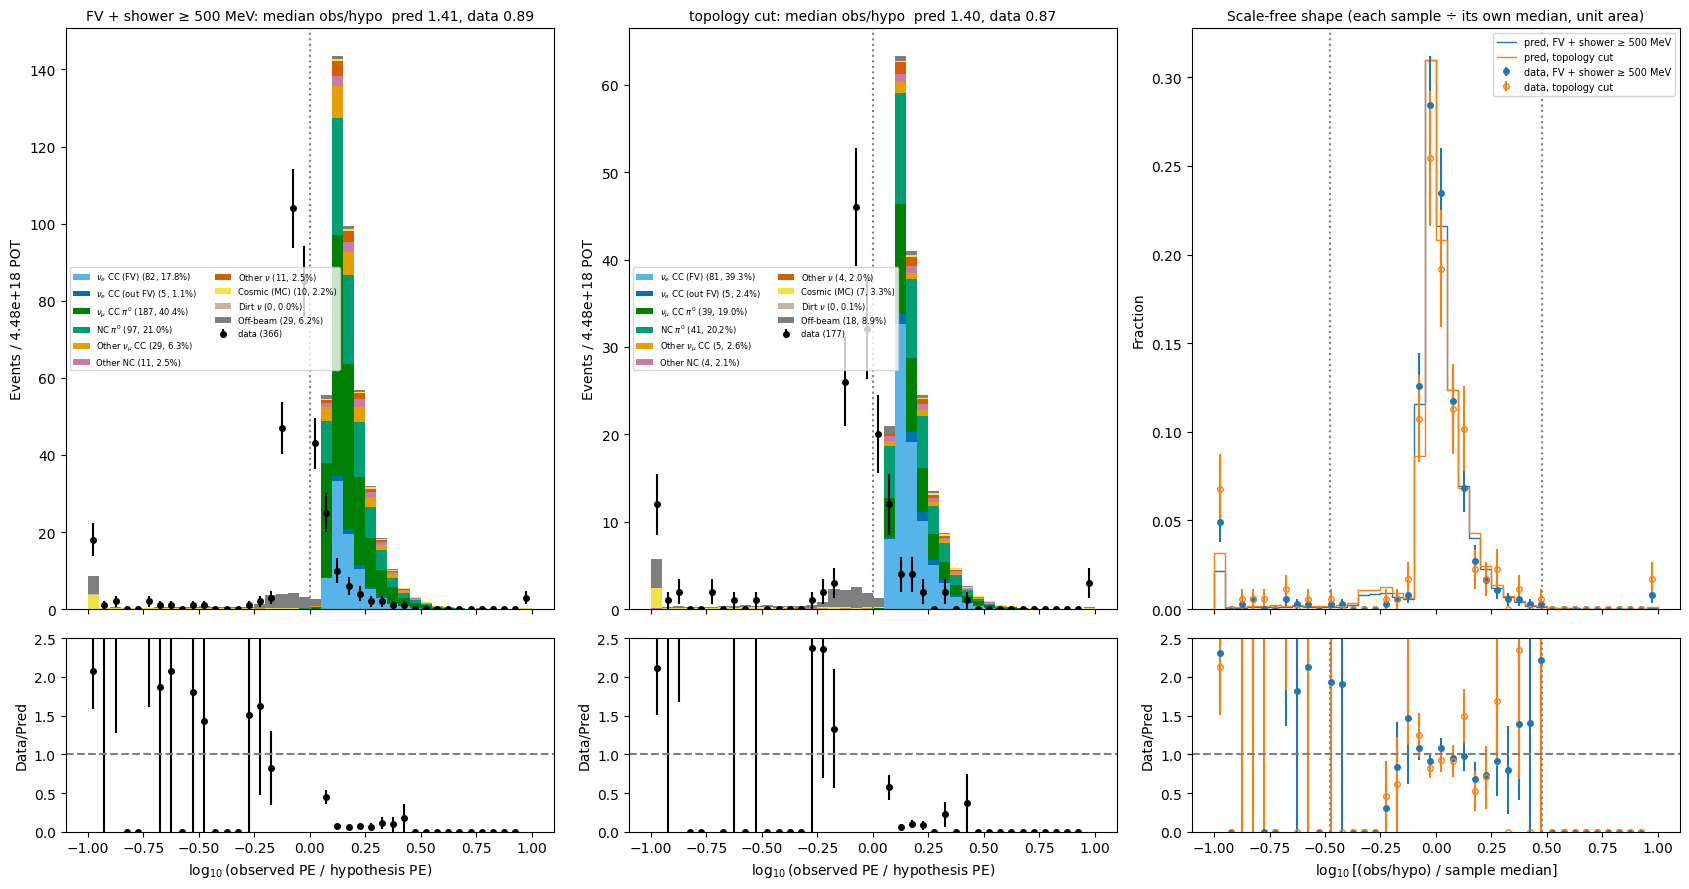

Observed / hypothesis PE. The median ratio is the light-yield scale; the tails are scale-free (more data in the tails than predicted → wrong matches in data):


,FV + shower ≥ 500 MeV,topology cut
"median obs/hypo, pred",1.41,1.40
"median obs/hypo, data",0.89,0.87
data/pred (light-yield scale),0.63,0.62
pred: % above ×3,0.30,0.40
pred: % below ÷3,3.20,4.79
data: % above ×3,0.82,1.69
data: % below ÷3,6.83,10.17
data: tail stat. err (%),1.45,2.59
n data,366.00,177.00


In [11]:
# Flash-match validation. The cut is binary (is_flash_matched == 1), so there is no cut value to vary,
# and a global light-yield scale changes PE / flash score without changing which flash is matched.
# A data/MC PE disagreement alone therefore does not mean the matching is biased. Three checks:
#   (a) MC match efficiency over all reco interactions (truth_info.passed_fm, before preselection)
#   (b) observed / hypothesis PE (hypothesis = OpT0Finder prediction from the charge):
#       the data/pred ratio of the medians measures the light-yield scale on its own
#   (c) the same ratio divided by each sample's own median → scale-free. More data in the tails
#       (flash much brighter / dimmer than the charge predicts) points to wrong matches
# (b, c) use the exported rows (leading shower ≥ KE_MIN), prediction at the data POT.
FM_NAMES = {0: 'nue CC FV, not signal', 1: 'nue CC out-FV', 2: 'numu CC pi0', 3: 'NC pi0',
            4: 'other numu CC', 5: 'other NC', 6: 'other nu', 7: 'cosmic'}
FM_TAIL = 3.0                                       # ratio/median beyond ×3 or ÷3 = tail
R_BINS  = np.linspace(-1.0, 1.0, 41)                # log10(obs/hypo), 0.05 wide
N_BINS  = np.linspace(-1.0, 1.0, 41)                # log10(ratio / sample median)

# ── (a) MC efficiency; truth_info keys are fixed format (read whole), so reduce key by key ─────
with pd.HDFStore(meta['files']['mc'], mode='r') as s:
    ti_keys = [k for k in s.keys() if k.startswith('/truth_info')]
fm_cat = 0
for k in ti_keys:
    t = pd.read_hdf(meta['files']['mc'], k)
    t = t.loc[~t['is_truth_only'].astype(bool)]
    t['grp'] = np.where(t['is_true_signal'].astype(bool), 'true signal',
                        t['truth_cat'].map(lambda c: FM_NAMES.get(c, str(c))))
    fm_cat = fm_cat + t.groupby('grp')['passed_fm'].agg(['size', 'sum']).astype(float)
    del t
    gc.collect()
fm_cat['eff %'] = 100 * fm_cat['sum'] / fm_cat['size']
print('MC flash-match efficiency per reco interaction (before preselection):')
display(fm_cat.rename(columns={'size': 'n reco int.', 'sum': 'n matched'}).round(1))


# ── (b, c) observed / hypothesis PE ─────────────────────────────────────────────────────────────
def with_ratio(d, stage):
    d = d[d[stage].fillna(False) & SHOWER(d).fillna(False)].copy()
    d['r'] = d['int_flash_total_pe'] / d['int_flash_hypo_pe']
    return d[np.isfinite(d['r']) & (d['r'] > 0)]


def wmedian(x, w):
    o = np.argsort(x.to_numpy())
    return float(np.interp(0.5, np.cumsum(w.to_numpy()[o]) / w.sum(), x.to_numpy()[o]))


def ratio_panel(ax, ar, c, h, tot):
    with np.errstate(divide='ignore', invalid='ignore'):
        ar.errorbar(c, h / tot, np.sqrt(h) / tot, fmt='ko', ms=4)
    ar.axhline(1, color='gray', ls='--'); ar.set_ylim(0, 2.5); ar.set_ylabel('Data/Pred')


STAGES_FM = [('sel_fiducial', f'FV + shower ≥ {KE_MIN:g} MeV'), ('sel_single_electron', 'topology cut')]
fig, axes = plt.subplots(2, 3, figsize=(3 * DATAMC_FIGSIZE[0], DATAMC_FIGSIZE[1]), gridspec_kw={'height_ratios': [3, 1]}, sharex='col')
rows = []
for j, (stage, slabel) in enumerate(STAGES_FM):
    p = with_ratio(PRED_D, stage)
    d = with_ratio(DATA, stage) if SHOW_DATA else None
    med_p = wmedian(p['r'], p['w'])
    med_d = float(d['r'].median()) if d is not None and len(d) else np.nan

    # (b) raw ratio, stacked by category
    ax, ar = axes[0, j], axes[1, j]
    p['_x'] = np.log10(p['r']).clip(R_BINS[0], R_BINS[-1] - 1e-9)
    tot = stacked(ax, p, '_x', R_BINS)
    c = 0.5 * (R_BINS[1:] + R_BINS[:-1])
    if d is not None:
        dc, _ = np.histogram(np.log10(d['r']).clip(R_BINS[0], R_BINS[-1] - 1e-9), bins=R_BINS)
        ax.errorbar(c, dc, np.sqrt(dc), fmt='ko', ms=4, label=f'data ({dc.sum()})')
        ratio_panel(ax, ar, c, dc, tot)
    ax.axvline(0, color='gray', ls=':')
    ax.set_title(f'{slabel}: median obs/hypo  pred {med_p:.2f}, data {med_d:.2f}', fontsize=10)
    ax.set_ylabel(f'Events / {DATA_POT:.2e} POT'); headroom(ax); ax.legend(fontsize=DATAMC_LEGEND_FS, ncol=2, frameon=False)
    ar.set_xlabel(r'$\log_{10}$(observed PE / hypothesis PE)')

    # (c) scale-free shape: each sample ÷ its own median, unit area
    xn_p = np.log10(p['r'] / med_p)
    hp, _ = np.histogram(xn_p.clip(N_BINS[0], N_BINS[-1] - 1e-9), bins=N_BINS, weights=p['w'])
    hp = hp / hp.sum()
    axes[0, 2].stairs(hp, N_BINS, color=f'C{j}', label=f'pred, {slabel}')
    hi, lo = xn_p > np.log10(FM_TAIL), xn_p < -np.log10(FM_TAIL)
    row = {'median obs/hypo, pred': med_p, 'median obs/hypo, data': med_d, 'data/pred (light-yield scale)': med_d / med_p,
           f'pred: % above ×{FM_TAIL:g}': 100 * p.loc[hi, 'w'].sum() / p['w'].sum(),
           f'pred: % below ÷{FM_TAIL:g}': 100 * p.loc[lo, 'w'].sum() / p['w'].sum()}
    if d is not None and len(d):
        xn_d = np.log10(d['r'] / med_d)
        hd, _ = np.histogram(xn_d.clip(N_BINS[0], N_BINS[-1] - 1e-9), bins=N_BINS)
        cn = 0.5 * (N_BINS[1:] + N_BINS[:-1])
        style = dict(fmt='o', ms=4, color=f'C{j}', mfc=f'C{j}' if j == 0 else 'none')
        axes[0, 2].errorbar(cn, hd / hd.sum(), np.sqrt(hd) / hd.sum(), label=f'data, {slabel}', **style)
        with np.errstate(divide='ignore', invalid='ignore'):
            axes[1, 2].errorbar(cn, hd / hd.sum() / hp, np.sqrt(hd) / hd.sum() / hp, **style)
        n_hi, n_lo = int((xn_d > np.log10(FM_TAIL)).sum()), int((xn_d < -np.log10(FM_TAIL)).sum())
        row.update({f'data: % above ×{FM_TAIL:g}': 100 * n_hi / len(d),
                    f'data: % below ÷{FM_TAIL:g}': 100 * n_lo / len(d),
                    'data: tail stat. err (%)': 100 * np.sqrt(max(n_hi + n_lo, 1)) / len(d),
                    'n data': len(d)})
    rows.append(pd.Series(row, name=slabel))

axes[0, 2].set_title('Scale-free shape (each sample ÷ its own median, unit area)', fontsize=10)
axes[0, 2].set_ylabel('Fraction'); axes[0, 2].legend(fontsize=DATAMC_LEGEND_FS, frameon=False)
for a in (axes[0, 2], axes[1, 2]):
    for x in (-np.log10(FM_TAIL), np.log10(FM_TAIL)):
        a.axvline(x, color='gray', ls=':')
axes[1, 2].axhline(1, color='gray', ls='--'); axes[1, 2].set_ylim(0, 2.5); axes[1, 2].set_ylabel('Data/Pred')
axes[1, 2].set_xlabel(r'$\log_{10}$[(obs/hypo) / sample median]')
fig.tight_layout(); savefig(fig, 'flash_match_validation')

print('Observed / hypothesis PE. The median ratio is the light-yield scale; the tails are scale-free '
      '(more data in the tails than predicted → wrong matches in data):')
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(pd.concat(rows, axis=1))

### 2.2b Flash matching vs. the data excess, and position dependence of the light yield
Answers Justin's point (the match is binary, a global light-yield factor does not change *which* flash is matched)
with the branches we have: (d) Data/Pred split by a **scale-free match quality**
$q=\log_{10}[(\mathrm{obs}/\mathrm{hypo})/\mathrm{sample\ median}]$ — wrong matches populate the tails, so an excess made of
wrong matches would show up only there; (e) the data/MC light-yield scale (ratio of median obs/hypo) vs drift
distance |x| and vs z — a flat scale is a global factor; a position-dependent one could change the matching.
Needs flash scores / times / unmatched interactions for more (next reprocess, see §2.2).

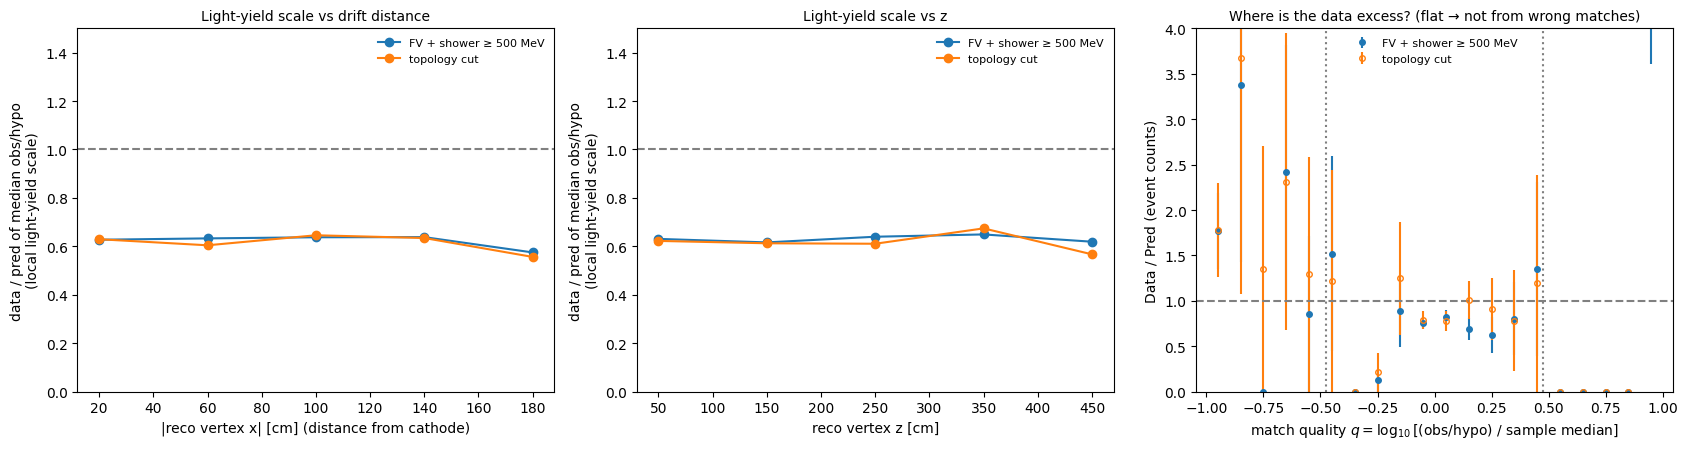

pred  data  data/pred  ± stat
stage                 events                                               
FV + shower ≥ 500 MeV all                  463.398   366      0.790   0.041
                      core (|q| < log10 3) 447.195   338      0.756   0.041
                      tails                 16.203    28      1.728   0.327
topology cut          all                  204.860   177      0.864   0.065
                      core (|q| < log10 3) 194.224   156      0.803   0.064
                      tails                 10.636    21      1.974   0.431

Reading: if data/pred in the core ≈ data/pred overall, the excess is not made of wrong flash matches. A flat light-yield scale vs |x| and z means a global PE scale (Justin's "simple factor"), which does not change which flash is matched.


In [12]:
# §2.2b — Does the data excess sit in badly matched events? Is the light scale position dependent?
# Uses only branches already exported (int_flash_total_pe, int_flash_hypo_pe, vtx_x/z).
#   (d) Data/Pred split by match quality. Quality is scale-free: q = log10[(obs/hypo) / sample median],
#       so the ~0.6 global light-yield difference is divided out. "core" = |q| < log10(FM_TAIL).
#       Wrong flash matches end up in the tails. If the vertex-plot excess came from wrong matches,
#       Data/Pred would be ≈1 in the core and ≫1 in the tails; a flat excess points elsewhere.
#   (e) Median obs/hypo vs drift distance |x| and vs z, data and prediction. The PDS sits at the
#       anodes (|x| ≈ 200 cm); a light-yield scale that changes with |x| or z means the light model
#       is mis-modelled in position, which is what could make the matching itself differ in data.
FM_X_BINS = np.array([0., 40., 80., 120., 160., 200.])        # |vtx_x| [cm], drift distance from cathode
FM_Z_BINS = np.array([0., 100., 200., 300., 400., 500.])      # vtx_z [cm]


def fm_quality(d, stage):
    d = with_ratio(d, stage)
    med = wmedian(d['r'], d['w']) if 'w' in d else float(d['r'].median())
    d['q'] = np.log10(d['r'] / med)
    d['core'] = d['q'].abs() < np.log10(FM_TAIL)
    return d, med


def ratio_err(n_d, n_p):
    return (n_d / n_p if n_p > 0 else np.nan,
            np.sqrt(max(n_d, 1)) / n_p if n_p > 0 else np.nan)


if not SHOW_DATA:
    print('SHOW_DATA is False → §2.2b needs on-beam data; skipped.')
else:
    rows = []
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    for j, (stage, slabel) in enumerate(STAGES_FM):
        p, _ = fm_quality(PRED_D, stage)
        d, _ = fm_quality(DATA.assign(w=1.0), stage)
        # (d) Data/Pred per match-quality class
        for name, mp, md in [('all', p.index == p.index, d.index == d.index),
                             (f'core (|q| < log10 {FM_TAIL:g})', p['core'], d['core']),
                             ('tails', ~p['core'], ~d['core'])]:
            n_p, n_d = p.loc[mp, 'w'].sum(), int(md.sum())
            r, e = ratio_err(n_d, n_p)
            rows.append(dict(stage=slabel, events=name, pred=n_p, data=n_d, **{'data/pred': r, '± stat': e}))
        # (e) median obs/hypo vs |x| and z
        for ax, var, edges, lab in [(axes[0], 'vtx_x', FM_X_BINS, r'|reco vertex x| [cm] (distance from cathode)'),
                                    (axes[1], 'vtx_z', FM_Z_BINS, 'reco vertex z [cm]')]:
            if var not in p.columns:
                ax.set_title(f'{var} not exported'); continue
            cen = 0.5 * (edges[1:] + edges[:-1])
            xp = p[var].abs() if var == 'vtx_x' else p[var]
            xd = d[var].abs() if var == 'vtx_x' else d[var]
            mp_, md_ = [], []
            for lo, hi in zip(edges[:-1], edges[1:]):
                sp, sd = p[(xp >= lo) & (xp < hi)], d[(xd >= lo) & (xd < hi)]
                mp_.append(wmedian(sp['r'], sp['w']) if len(sp) > 5 else np.nan)
                md_.append(float(sd['r'].median()) if len(sd) > 5 else np.nan)
            mp_, md_ = np.array(mp_), np.array(md_)
            ax.plot(cen, md_ / mp_, 'o-', color=f'C{j}', label=slabel)
            ax.set_xlabel(lab)
        # (d) as a plot: data/pred vs q
        qb = np.linspace(-1, 1, 21)
        hp, _ = np.histogram(p['q'].clip(qb[0], qb[-1] - 1e-9), bins=qb, weights=p['w'])
        hd, _ = np.histogram(d['q'].clip(qb[0], qb[-1] - 1e-9), bins=qb)
        with np.errstate(divide='ignore', invalid='ignore'):
            axes[2].errorbar(0.5 * (qb[1:] + qb[:-1]), hd / hp, np.sqrt(hd) / hp, fmt='o', color=f'C{j}',
                             mfc=f'C{j}' if j == 0 else 'none', ms=4, label=slabel)
    for ax in axes[:2]:
        ax.axhline(1, color='gray', ls='--'); ax.set_ylabel('data / pred of median obs/hypo\n(local light-yield scale)')
        ax.set_ylim(0, 1.5); ax.legend(fontsize=8, frameon=False)
    axes[0].set_title('Light-yield scale vs drift distance', fontsize=10)
    axes[1].set_title('Light-yield scale vs z', fontsize=10)
    axes[2].axhline(1, color='gray', ls='--')
    for x in (-np.log10(FM_TAIL), np.log10(FM_TAIL)):
        axes[2].axvline(x, color='gray', ls=':')
    axes[2].set_ylim(0, 4); axes[2].set_ylabel('Data / Pred (event counts)')
    axes[2].set_xlabel(r'match quality $q=\log_{10}$[(obs/hypo) / sample median]')
    axes[2].set_title('Where is the data excess? (flat → not from wrong matches)', fontsize=10)
    axes[2].legend(fontsize=8, frameon=False)
    fig.tight_layout(); savefig(fig, 'flash_match_excess_vs_quality')

    FM_EXCESS = pd.DataFrame(rows).set_index(['stage', 'events'])
    with pd.option_context('display.float_format', '{:.3f}'.format):
        display(FM_EXCESS)
    print('Reading: if data/pred in the core ≈ data/pred overall, the excess is not made of wrong flash matches. '
          'A flat light-yield scale vs |x| and z means a global PE scale (Justin\'s "simple factor"), '
          'which does not change which flash is matched.')


### 2.2c ν-triggered gate fraction f (cosmic normalization) and its stability
The off-beam data and in-time MC are scaled by $(1-f)\,G_\mathrm{BNB}/G_\mathrm{cosmic}$, where $f$ is the fraction of BNB
gates whose trigger came from a neutrino. $f$ is measured from the data set itself, $f=(R_\mathrm{on}-R_\mathrm{off})/(1-R_\mathrm{off})$
with $R$ = triggered events per gate; nue_syst.ipynb §1.4 computes the same value and uses it. Here: its value per
chunk of data files — a drifting trigger rate would make one global $f$ wrong for part of the data.

R_on  = 88,046 / 927,556 = 9.4923%
R_off = 1,660,552 / 83,691,835 = 1.9841%
f     = 0.0766 ± 0.0003 (stat)   (old fixed value 0.0725)


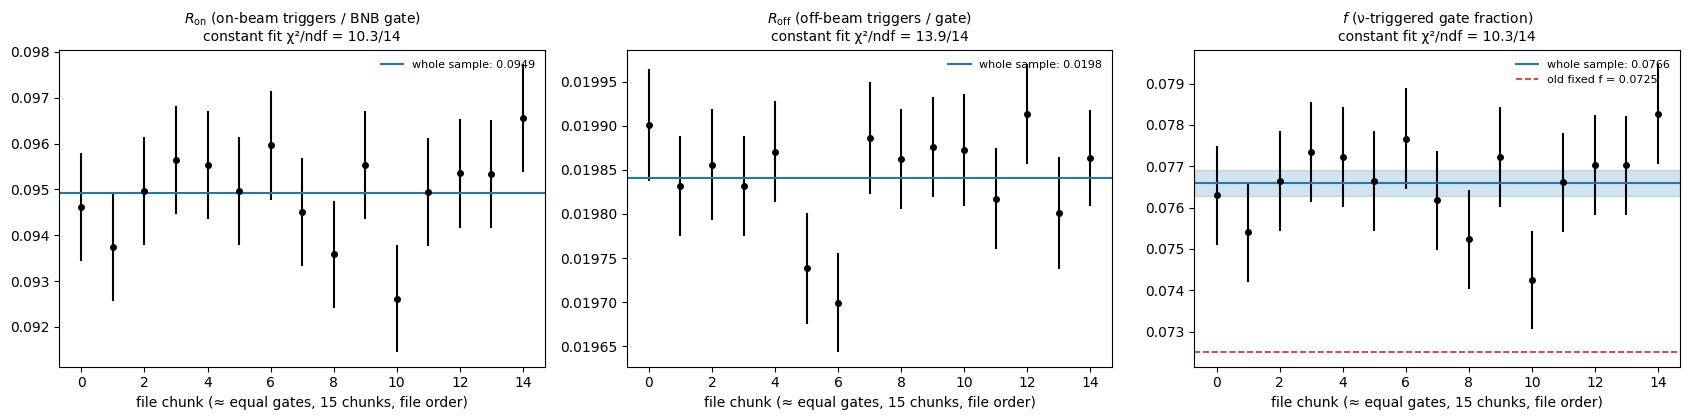

cosmic scale change vs the old fixed f: (1 − f)/(1 − 0.0725) = 0.9956


In [13]:
# §2.2c — ν-triggered gate fraction f: value used by nue_syst.ipynb (§1.4) and its stability across the data.
#   scale(cosmic sample) = (1 − f)·G_BNB / G_cosmic,   f = (R_on − R_off) / (1 − R_off)
#   R_on / R_off = triggered events per gate in on-beam / off-beam data.
# Chunks follow the file order of each sample (≈ time order for the dev / off-beam lists). A trigger
# rate that drifts between chunks (trigger threshold, PMT gain, beam intensity) would make one global
# f (and thus the cosmic normalization) wrong for part of the data.
import nue_helpers as nh

F_N_CHUNKS = 15
F_TRIG = nh.nu_trigger_fraction(DATA_FILE, OFFBEAM_FILE)
print(f"R_on  = {F_TRIG['n_trig_on']:,} / {F_TRIG['gates_on']:,} = {F_TRIG['r_on']:.4%}")
print(f"R_off = {F_TRIG['n_trig_off']:,} / {F_TRIG['gates_off']:,} = {F_TRIG['r_off']:.4%}")
print(f"f     = {F_TRIG['f']:.4f} ± {F_TRIG['f_err']:.4f} (stat)   (old fixed value {nh.BEAM_DUTY_FRACTION})")


def _rate_by_file(path, kind):
    """Gates and triggered events per input file (__ntuple), in file order."""
    hdr = nh._all_hdr(path)
    trig = hdr.groupby(level=0).size()
    if kind == 'on':
        with pd.HDFStore(path, mode='r') as st:
            pot = pd.concat([st[k] for k in st.keys() if re.match(r'^/pot_\d+$', k)])
        gates = (pot['TOR860'] > 0).groupby(level=0).sum()
    else:
        first = hdr[hdr['first_in_subrun'].astype(bool)]
        gates = first['noffbeambnb'].groupby(level=0).sum()
    d = pd.DataFrame({'gates': gates, 'trig': trig}).fillna(0).sort_index()
    d = d[d['gates'] > 0]
    d['chunk'] = np.minimum((d['gates'].cumsum() / d['gates'].sum() * F_N_CHUNKS).astype(int), F_N_CHUNKS - 1)
    c = d.groupby('chunk')[['gates', 'trig']].sum()
    c['r'] = c['trig'] / c['gates']
    c['e'] = np.sqrt(c['r'] * (1 - c['r']) / c['gates'])
    return c


def _const_chi2(y, e):
    w = 1 / e ** 2
    m = np.sum(w * y) / np.sum(w)
    return m, float(np.sum(((y - m) / e) ** 2)), len(y) - 1


F_ON, F_OFF = _rate_by_file(DATA_FILE, 'on'), _rate_by_file(OFFBEAM_FILE, 'off')
r_off = F_TRIG['r_off']
F_ON['f'] = (F_ON['r'] - r_off) / (1 - r_off)
F_ON['f_e'] = F_ON['e'] / (1 - r_off)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for ax, c, ycol, ecol, lab, ref in [(axes[0], F_ON, 'r', 'e', r'$R_\mathrm{on}$ (on-beam triggers / BNB gate)', F_TRIG['r_on']),
                                    (axes[1], F_OFF, 'r', 'e', r'$R_\mathrm{off}$ (off-beam triggers / gate)', F_TRIG['r_off']),
                                    (axes[2], F_ON, 'f', 'f_e', r'$f$ (ν-triggered gate fraction)', F_TRIG['f'])]:
    m, c2, ndf = _const_chi2(c[ycol].to_numpy(), c[ecol].to_numpy())
    ax.errorbar(c.index, c[ycol], c[ecol], fmt='ko', ms=4)
    ax.axhline(ref, color='C0', lw=1.5, label=f'whole sample: {ref:.4f}')
    ax.set_title(f'{lab}\nconstant fit χ²/ndf = {c2:.1f}/{ndf}', fontsize=10)
    ax.set_xlabel(f'file chunk (≈ equal gates, {F_N_CHUNKS} chunks, file order)')
axes[2].axhline(nh.BEAM_DUTY_FRACTION, color='C3', ls='--', lw=1.2, label=f'old fixed f = {nh.BEAM_DUTY_FRACTION}')
axes[2].axhspan(F_TRIG['f'] - F_TRIG['f_err'], F_TRIG['f'] + F_TRIG['f_err'], color='C0', alpha=0.2)
for ax in axes:
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout(); savefig(fig, 'nu_trigger_fraction_stability')
print(f"cosmic scale change vs the old fixed f: (1 − f)/(1 − {nh.BEAM_DUTY_FRACTION}) = "
      f"{(1 - F_TRIG['f']) / (1 - nh.BEAM_DUTY_FRACTION):.4f}")


### 2.2d Flash-match variables of all reco interactions, before the flash-match and FV cuts (Lynn TN Fig. 1 style)
Needs the `flash_<k>` tables (one row per reco interaction, before any cut) written by the updated makedf
(`make_nuecc_flashdf` / `make_nuecc_flashdf_data`); until the samples are re-processed the cell only reports
that they are missing. Data/MC of the matched-flash PE (unmatched interactions in their own bin), time, score and
observed/hypothesis PE, plus the flash-match pass rate and a PE-threshold scan in data vs prediction — the
behaviour of the cut itself before deciding on it.

In [14]:
# §2.2d — Flash-match variables of ALL reco interactions, BEFORE the flash-match and FV cuts
# (Lynn TN Fig. 1 style), from the flash_<k> tables written by make_nueCC_df.make_nuecc_flashdf(_data).
#   (a) matched-flash PE for every interaction; interactions without a match go in the 'unmatched' bin
#       (OpT0Finder only stores a flash for the winning match, so unmatched ones have no PE / time / score)
#   (b) matched-flash time for matched interactions with PE > FM_PE_MIN (Lynn: 2000 PE)
#   (c) matched-flash score (SPINE stores only the winning match: no runner-up score)
#   (d) observed / hypothesis PE for matched interactions
# Two stages: all reco interactions, and reco vertex in FV (still before the flash match).
# Prediction = MC (BNB+cosmics, cosmic-only rows prescaled → weight w_prescale) + dirt + off-beam,
# scaled to the data POT with the same factors as the CSV export (meta['scales']).
# Table: flash-match pass rate (the current cut) in data vs prediction, and a PE-threshold scan of
# the same rate — the data/MC behaviour of the cut before choosing it.
FM_PE_MIN = 2000.0
FLASH_SAMPLES = {   # name: (file, weight to data POT, fixed plot category or None = truth_cat)
    'mc':      (DF_FILE,      meta['scales']['mc_to_data'],      None),
    'dirt':    (LOWE_FILE,    meta['scales']['dirt_to_data'],    9),
    'offbeam': (OFFBEAM_FILE, meta['scales']['offbeam_to_data'], 8),
    'data':    (DATA_FILE,    1.0,                               None),
}
FLASH_VARS = {
    'pe':    (np.r_[0.5, np.linspace(1.0, 5.5, 37)], r'$\log_{10}$(matched flash PE)   [left bin: unmatched]'),
    'time':  (np.linspace(-2.0, 4.0, 61),           r'matched flash time [$\mu$s]  (PE > %g)' % FM_PE_MIN),
    'score': (np.linspace(-1.0, 5.0, 37),           r'$\log_{10}$(matched flash score)'),
    'ratio': (np.linspace(-1.0, 1.5, 41),           r'$\log_{10}$(observed PE / hypothesis PE)'),
}
FLASH_STAGES = {'all': 'all reco interactions', 'fv': 'reco vertex in FV (before flash match)'}
PE_SCAN = np.array([0, 500, 1000, 2000, 3000, 5000, 8000])


def _flash_keys(path):
    if not os.path.exists(path):
        return []
    with pd.HDFStore(path, mode='r') as st:
        return sorted((k for k in st.keys() if re.match(r'^/flash_\d+$', k)), key=lambda k: int(k.split('_')[-1]))


def _flash_values(t):
    pe = t['flash_total_pe'].to_numpy(float)
    m = (t['is_flash_matched'].to_numpy() == 1) & (pe > 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        return m, {
            'pe':    np.where(m, np.log10(np.where(m, pe, 1)), 0.75),
            'time':  np.where(m & (pe > FM_PE_MIN), t['flash_time'].to_numpy(float), np.nan),
            'score': np.where(m, np.log10(t['flash_score'].to_numpy(float)), np.nan),
            'ratio': np.where(m, np.log10(pe / t['flash_hypo_pe'].to_numpy(float)), np.nan),
        }


def _accumulate():
    H = {(st, v): {} for st in FLASH_STAGES for v in FLASH_VARS}      # pred: per category
    D = {(st, v): None for st in FLASH_STAGES for v in FLASH_VARS}     # data
    RATE = {(s, st): np.zeros(2) for s in ('pred', 'data') for st in FLASH_STAGES}   # (Σw, Σw passed_fm)
    SCAN = {(s, st): np.zeros(len(PE_SCAN) + 1) for s in ('pred', 'data') for st in FLASH_STAGES}
    found = {}
    for name, (path, scale, fixed) in FLASH_SAMPLES.items():
        keys = _flash_keys(path)
        found[name] = len(keys)
        if name == 'data' and not SHOW_DATA:
            continue
        for k in keys:
            t = pd.read_hdf(path, k)
            if t.empty:
                continue
            w = scale * t['w_prescale'].to_numpy(float)
            cat = (np.full(len(t), fixed) if fixed is not None else
                   (t['truth_cat'].to_numpy() if 'truth_cat' in t else np.full(len(t), 7)))
            matched, vals = _flash_values(t)
            pe = t['flash_total_pe'].to_numpy(float)
            side = 'data' if name == 'data' else 'pred'
            for st in FLASH_STAGES:
                sm = np.ones(len(t), bool) if st == 'all' else t['passed_fv_reco'].to_numpy(bool)
                RATE[(side, st)] += [w[sm].sum(), w[sm & t['passed_fm'].to_numpy(bool)].sum()]
                SCAN[(side, st)] += np.r_[w[sm].sum(), [w[sm & t['passed_fm'].to_numpy(bool) & (pe > p)].sum()
                                                        for p in PE_SCAN]]
                for v, (bins, _) in FLASH_VARS.items():
                    x = vals[v]
                    ok = sm & np.isfinite(x)
                    xc = np.clip(x[ok], bins[0], bins[-1] - 1e-9)
                    if side == 'data':
                        h, _ = np.histogram(xc, bins=bins)
                        D[(st, v)] = h if D[(st, v)] is None else D[(st, v)] + h
                    else:
                        for c in np.unique(cat[ok]):
                            mc_ = cat[ok] == c
                            h, _ = np.histogram(xc[mc_], bins=bins, weights=w[ok][mc_])
                            H[(st, v)][int(c)] = H[(st, v)].get(int(c), 0) + h
            del t
            gc.collect()
    return H, D, RATE, SCAN, found


FH, FD, FRATE, FSCAN, _found = _accumulate()
print('flash_<k> keys found:', _found)
if _found.get('mc', 0) == 0:
    print('No flash_<k> tables in the MC file → re-process with the updated makedf '
          '(nueCC_mc.py / nueCC_data.py now write "flash"), then re-run this cell.')
else:
    for v, (bins, xlabel) in FLASH_VARS.items():
        fig, axes = plt.subplots(2, len(FLASH_STAGES), figsize=(DATAMC_FIGSIZE[0] * len(FLASH_STAGES), DATAMC_FIGSIZE[1]), sharex=True,
                                 gridspec_kw={'height_ratios': [3, 1]}, squeeze=False)
        for j, (st, slabel) in enumerate(FLASH_STAGES.items()):
            ax, ar = axes[0, j], axes[1, j]
            bottom, tot_all = np.zeros(len(bins) - 1), sum(np.sum(h) for h in FH[(st, v)].values())
            for c in ORDER:
                h = FH[(st, v)].get(c)
                if h is None or np.sum(h) <= 0:
                    continue
                ax.bar(bins[:-1], h, width=np.diff(bins), bottom=bottom, align='edge', color=CAT[c][1], edgecolor='none',
                       label=f'{CAT[c][0]} ({np.sum(h):.0f}, {100 * np.sum(h) / max(tot_all, 1e-9):.1f}%)')
                bottom += h
            cen = 0.5 * (bins[1:] + bins[:-1])
            if FD[(st, v)] is not None:
                dh = FD[(st, v)]
                ax.errorbar(cen, dh, np.sqrt(dh), fmt='ko', ms=3, label=f'data ({dh.sum()})')
                with np.errstate(divide='ignore', invalid='ignore'):
                    ar.errorbar(cen, dh / bottom, np.sqrt(dh) / bottom, fmt='ko', ms=3)
                ax.set_title(f'{slabel}: data/pred = {dh.sum() / bottom.sum():.3f}', fontsize=10)
            else:
                ax.set_title(slabel, fontsize=10)
            if v == 'pe':
                ax.axvline(1.0, color='gray', lw=0.8)
                ax.axvline(np.log10(FM_PE_MIN), color='C3', ls='--', lw=1, label=f'{FM_PE_MIN:g} PE (Lynn N1)')
            ax.set_yscale('log'); ax.set_ylabel(f'Interactions / {DATA_POT:.2e} POT'); headroom(ax)
            ax.legend(fontsize=DATAMC_LEGEND_FS, ncol=2, frameon=False)
            ar.axhline(1, color='gray', ls='--'); ar.set_ylim(0, 2); ar.set_ylabel('Data/Pred'); ar.set_xlabel(xlabel)
            if v == 'pe':
                ar.set_xticks([0.75, 1, 2, 3, 4, 5]); ar.set_xticklabels(['unmatched', '1', '2', '3', '4', '5'], fontsize=8)
        fig.tight_layout(); savefig(fig, f'raw_flash_{v}')

    rows = []
    for st, slabel in FLASH_STAGES.items():
        p, d = FRATE[('pred', st)], FRATE[('data', st)]
        row = {'stage': slabel, 'pred: interactions': p[0], 'pred: FM pass rate': p[1] / max(p[0], 1e-9)}
        if d[0] > 0:
            rd = d[1] / d[0]
            row.update({'data: interactions': d[0], 'data: FM pass rate': rd,
                        '± stat': np.sqrt(rd * (1 - rd) / d[0]),
                        'data/pred (interactions)': d[0] / p[0], 'data/pred (FM rate)': rd / (p[1] / p[0])})
        rows.append(row)
    print('Flash-match pass rate before the cut (data vs prediction):')
    with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 220):
        display(pd.DataFrame(rows).set_index('stage'))

    rows = []
    for st, slabel in FLASH_STAGES.items():
        p, d = FSCAN[('pred', st)], FSCAN[('data', st)]
        for i, thr in enumerate(PE_SCAN):
            row = {'stage': slabel, 'PE >': thr, 'pred: pass rate': p[i + 1] / max(p[0], 1e-9)}
            if d[0] > 0:
                row.update({'data: pass rate': d[i + 1] / d[0],
                            'data/pred': (d[i + 1] / d[0]) / max(p[i + 1] / max(p[0], 1e-9), 1e-12)})
            rows.append(row)
    print('Flash match + matched-flash PE threshold: pass rate vs threshold (a flat data/pred means the PE '
          'cut does not change the data/MC balance):')
    with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 220):
        display(pd.DataFrame(rows).set_index(['stage', 'PE >']))


flash_<k> keys found: {'mc': 0, 'dirt': 0, 'offbeam': 0, 'data': 0}
No flash_<k> tables in the MC file → re-process with the updated makedf (nueCC_mc.py / nueCC_data.py now write "flash"), then re-run this cell.


## 2.3 Sideband regions in dE/dx – conversion gap (Lynn DAP Fig. 2 style)
MC only, FV + leading e/γ shower ≥ KE_MIN (Lynn applied θ_open > 0.1 rad first; SPINE has no opening angle, so nothing is pre-applied).
Gap = 0 is drawn in the lowest bin.

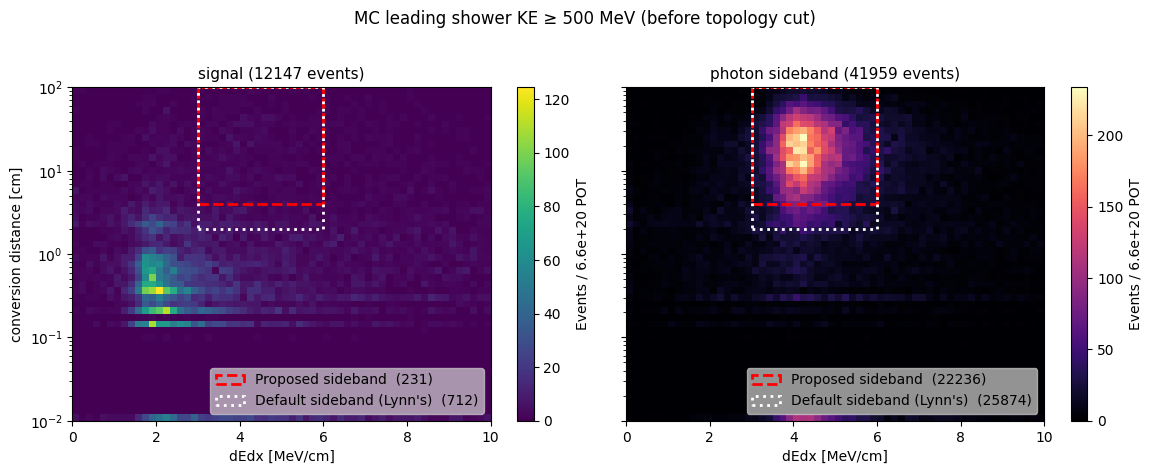

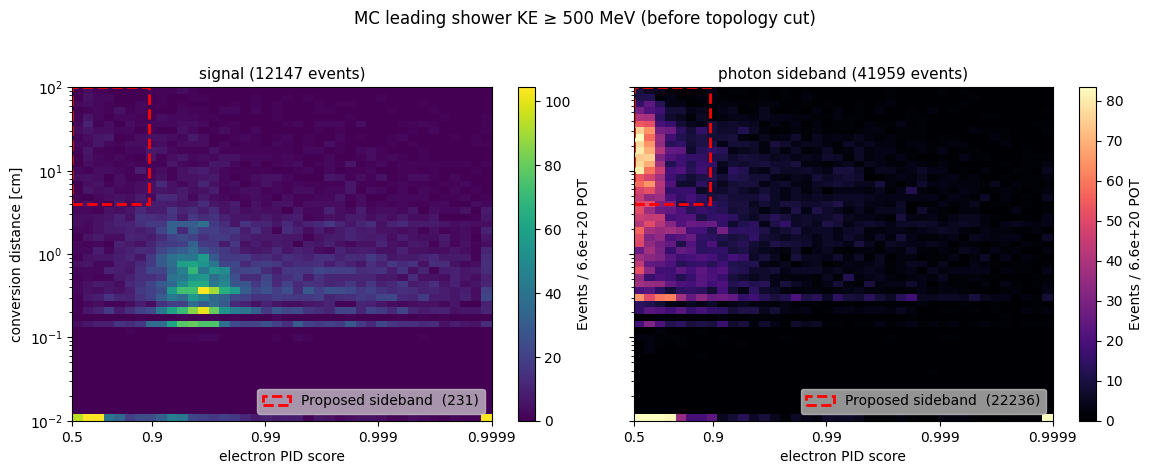

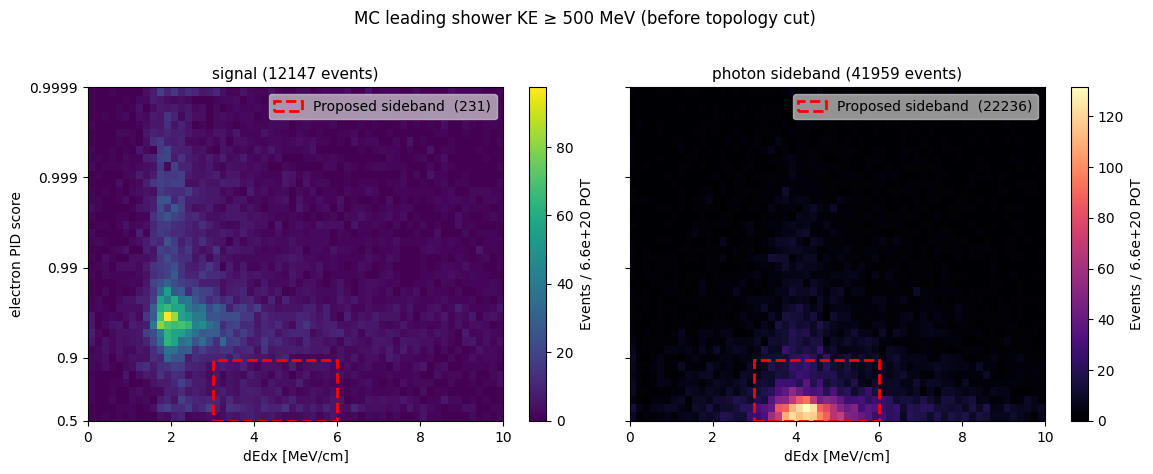

In [15]:
# 2D sideband views, signal vs photon sideband. Three projections per population:
#   dE/dx vs gap  (my SB box + Lynn's TN box),  PID vs gap  and  dE/dx vs PID  (my SB box only).
# Axes: gap on a log scale (gap = 0 is drawn in the lowest bin); PID score on a log scale in
# (1 − score), so the region near 1.0, where most events sit, is stretched out.
# Legend numbers = events in that panel passing ALL conditions of the box (not only the two drawn).

MY_SB = dict(  # current sideband definition (nue_selection THRESH_*)
    label="Proposed sideband",
    cuts={'gap':  (THR.get('THRESH_VERTEX_DIST', 3.45), np.inf),
          'dedx': (THR.get('THRESH_SB_DEDX_LO', 3.0), THR.get('THRESH_SB_DEDX_HI', 6.0)),
          'pid':  (-np.inf, THR.get('THRESH_PID_SCORE', 0.91))},
    color='red', ls='--')
LYNN_SB = dict(label="Default sideband (Lynn's)",
               cuts={'gap': (2.0, np.inf), 'dedx': (3.0, 6.0)},
               color='white', ls=':')

PID_FLOOR = 1e-4                       # axis ends at PID = 1 − 1e-4; scores above go in the last bin
_pid_fwd = lambda p: -np.log10(np.clip(1.0 - np.asarray(p, float), PID_FLOOR * 1e-2, None))
_pid_inv = lambda t: 1.0 - 10.0 ** (-np.asarray(t, float))

AXES = {
    # key: (column suffix, bin edges, label, scale)
    'dedx': (
        'start_dedx',
        np.linspace(0, 10, 61),
        'dEdx [MeV/cm]',
        'linear',
    ),
    'gap': (
        'vertex_distance',
        np.logspace(-2, 2, 51),
        'conversion distance [cm]',
        'log',
    ),
    'pid': (
        'pid_score_electron',
        1.0 - np.logspace(
            np.log10(0.5),
            np.log10(PID_FLOOR),
            41,
        ),
        'electron PID score',
        'pid',
    ),
}


def _axis_values(dp, v, key):
    col, edges, _, scale = AXES[key]
    x = dp[v + col].to_numpy(float)
    if scale == 'log':          # gap = 0 → lowest bin
        x = np.where(np.isfinite(x), np.maximum(x, edges[0] * 1.001), x)
    elif scale == 'pid':        # scores ≈ 1 → last bin
        x = np.where(np.isfinite(x), np.minimum(x, edges[-1] - PID_FLOOR * 1e-3), x)
    return x


def _set_scale(ax, key, which):
    _, edges, _, scale = AXES[key]
    setlim, setscale, setticks, setlabels = (
        (ax.set_xlim, ax.set_xscale, ax.set_xticks, ax.set_xticklabels) if which == 'x'
        else (ax.set_ylim, ax.set_yscale, ax.set_yticks, ax.set_yticklabels))
    if scale == 'log':
        setscale('log')
    elif scale == 'pid':
        setscale('function', functions=(_pid_fwd, _pid_inv))
        ticks = [0.5, 0.9, 0.99, 0.999, 0.9999]
        setticks(ticks); setlabels([f'{t:g}' for t in ticks])
    setlim(edges[0], edges[-1])


def _in_box(d, v, box):
    m = pd.Series(True, index=d.index)
    for key, (lo, hi) in box['cuts'].items():
        x = d[v + AXES[key][0]]
        m &= (x > lo) & (x < hi)
    return m.fillna(False)


def fig_sb2d(pre, v, xkey, ykey, boxes, name, suptitle='', colorbar=True):
    d = PRED_T[pre(PRED_T).fillna(False)]
    panels = [('signal', d['pcat'] == 0, 'viridis'),
              ('photon sideband', d['pcat'].isin([2, 3]), 'magma')]
    (_, xb, xl, _), (_, yb, yl, _) = AXES[xkey], AXES[ykey]
    fig, axes = plt.subplots(1, len(panels), figsize=(5.4 * len(panels) + (1 if colorbar else 0), 4.6),
                             sharey=True, squeeze=False)
    for ax, (title, m, cmap) in zip(axes[0], panels):
        cm = plt.get_cmap(cmap)
        ax.set_facecolor(cm(0.0))
        dp = d[m.to_numpy()]
        x, y, w = _axis_values(dp, v, xkey), _axis_values(dp, v, ykey), dp['w'].to_numpy(float)
        ok = np.isfinite(x) & np.isfinite(y)
        h, _, _ = np.histogram2d(x[ok], y[ok], bins=[xb, yb], weights=w[ok])
        # gap = 0 (shower attached to the vertex) piles up in the lowest gap row: keep it out of the colour range
        vmax = h[:, 1:].max() if (ykey == 'gap' and h[:, 1:].max() > 0) else h.max()
        im = ax.pcolormesh(xb, yb, h.T, cmap=cm, norm=plt.Normalize(vmin=0, vmax=max(vmax, 1e-9)), shading='flat')
        if colorbar:
            fig.colorbar(im, ax=ax, label=f'Events / {TARGET_POT:.1e} POT')
        for box in boxes:
            (x0, x1), (y0, y1) = [box['cuts'].get(k, (-np.inf, np.inf)) for k in (xkey, ykey)]
            x0, x1 = max(x0, xb[0]), min(x1, xb[-1])
            y0, y1 = max(y0, yb[0]), min(y1, yb[-1])
            n_in = dp.loc[_in_box(dp, v, box), 'w'].sum()
            ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=box['color'],
                                            ls=box['ls'], lw=2, label=f"{box['label']}  ({n_in:.0f})"))
        _set_scale(ax, xkey, 'x'); _set_scale(ax, ykey, 'y')
        ax.set_title(f'{title} ({w.sum():.0f} events)', fontsize=11)
        ax.set_xlabel(xl)
        ax.legend(loc='lower right' if ykey == 'gap' else 'upper right', fontsize=10,
                  facecolor='lightgray', framealpha=0.7)
    axes[0][0].set_ylabel(yl)
    if suptitle:
        fig.suptitle(suptitle, y=1.02)
    fig.tight_layout()
    savefig(fig, name)


def sb2d_set(pre, v, tag, suptitle):
    fig_sb2d(pre, v, 'dedx', 'gap', [MY_SB, LYNN_SB], f'sb2d_{tag}_dedx_gap', suptitle)
    fig_sb2d(pre, v, 'pid',  'gap', [MY_SB],          f'sb2d_{tag}_pid_gap',  suptitle)
    fig_sb2d(pre, v, 'dedx', 'pid', [MY_SB],          f'sb2d_{tag}_dedx_pid', suptitle)


# Set 1 (Lynn DAP Fig. 2 analogue): FV + leading e/γ shower (SPINE PID 0 or 1) with KE ≥ KE_MIN
sb2d_set(SHOWER, 'sh_', 'leading_shower',
         f'MC leading shower KE ≥ {KE_MIN:g} MeV (before topology cut)')


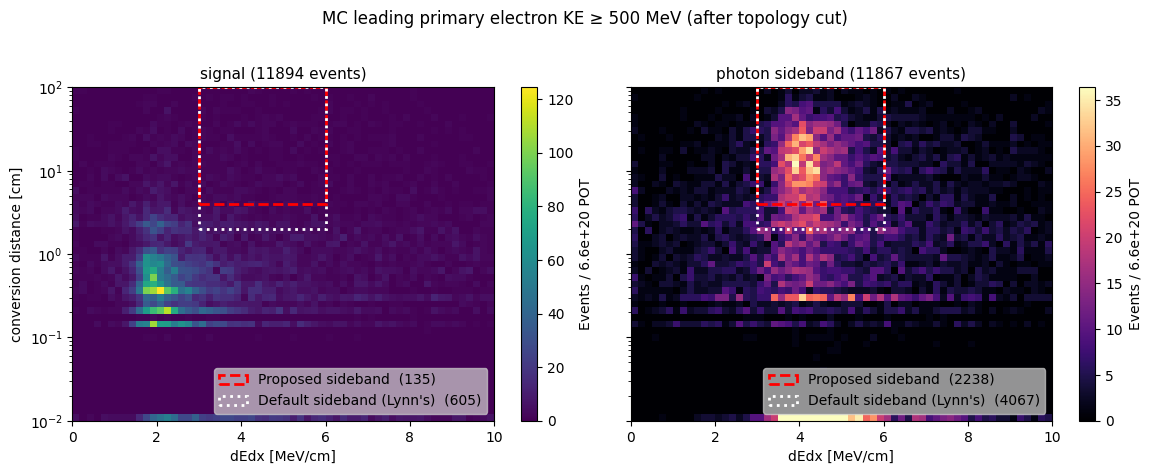

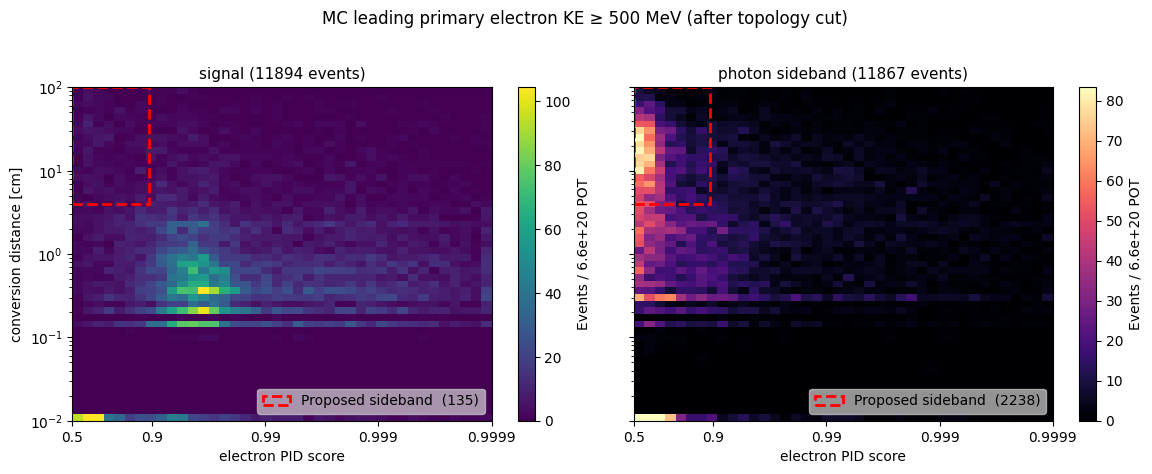

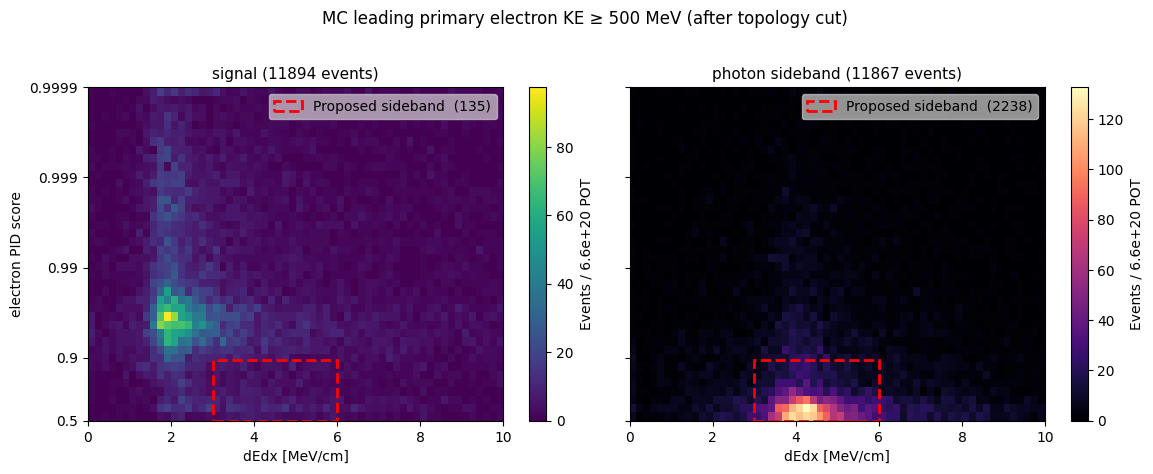

In [16]:
# Set 2: events passing the topology cut (≥1 primary reco electron ≥ 500 MeV), leading SPINE electron —
# the particle the signal selection and the sideband actually cut on.
sb2d_set(lambda d: d['sel_single_electron'], EP, 'topology',
         f'MC leading primary electron KE ≥ {KE_MIN:g} MeV (after topology cut)')

## 2.4 Sideband definitions: size, signal contamination, composition

In [17]:
POTS = [DATA_POT, 3e19, 1e20, 8.81e19]
 
def sb_table():
    rows = []
    for name in SIDEBANDS:
        d = PRED_T[in_sb(PRED_T, name)]
        tot = d['w'].sum()
        by = d.groupby('pcat')['w'].sum()
        f = lambda *cs: 100 * sum(by.get(c, 0) for c in cs) / tot if tot > 0 else np.nan
        row = {'sideband': name, 'νe CC FV %': f(0), 'νe all %': f(0, 1), 'νμCCπ0 %': f(2), 'NCπ0 %': f(3),
               'other ν %': f(4, 5, 6, 9), 'cosmic+offbeam %': f(7, 8)}
        for p in POTS:
            row[f'N @ {p:.2e}'] = tot * p / TARGET_POT
        if SHOW_DATA:
            row['data (dev)'] = int(in_sb(DATA, name).sum())
        rows.append(row)
    return pd.DataFrame(rows).set_index('sideband')
 
SB_TABLE = sb_table()
SB_TABLE.to_csv(f'{PLOT_DIR}/sideband_definitions.csv')
with pd.option_context('display.float_format', '{:.1f}'.format, 'display.width', 200):
    display(SB_TABLE)


,νe CC FV %,νe all %,νμCCπ0 %,NCπ0 %,other ν %,cosmic+offbeam %,N @ 4.48e+18,N @ 3.00e+19,N @ 1.00e+20,N @ 8.81e+19,data (dev)
sideband,,,,,,,,,,,
"Lynn TN: gap>2, 3<dE/dx<6",2.1,2.6,53.5,27.5,10.4,6.1,216.7,1452.3,4841.2,4265.1,149
"Lynn DAP cons.: gap>1, 3–6",2.9,3.4,53.4,27.0,10.2,6.0,228.7,1533.1,5110.3,4502.2,165
"Lynn DAP loose: gap>0.1, 3–6",6.7,7.2,49.7,25.7,9.4,8.0,264.7,1774.1,5913.6,5209.9,194
SPINE γ-PID leading shower,0.5,0.6,59.0,22.4,12.0,6.0,249.9,1675.3,5584.2,4919.7,188
SPINE γ-PID + Lynn TN box,0.4,0.4,58.7,25.0,11.3,4.6,176.9,1185.7,3952.4,3482.1,123
"Proposed: gap>3.95, PID<0.895, 3<dE/dx<6",4.3,7.4,23.8,47.2,6.8,14.8,21.4,143.4,478.1,421.2,18
Lynn TN box + contained (≈D1),3.1,3.7,37.6,40.6,10.1,8.0,137.4,920.7,3069.1,2703.9,96


## 2.5 Control region: leading-shower energy by category and by reco PID (Lynn DAP Fig. 1 style)

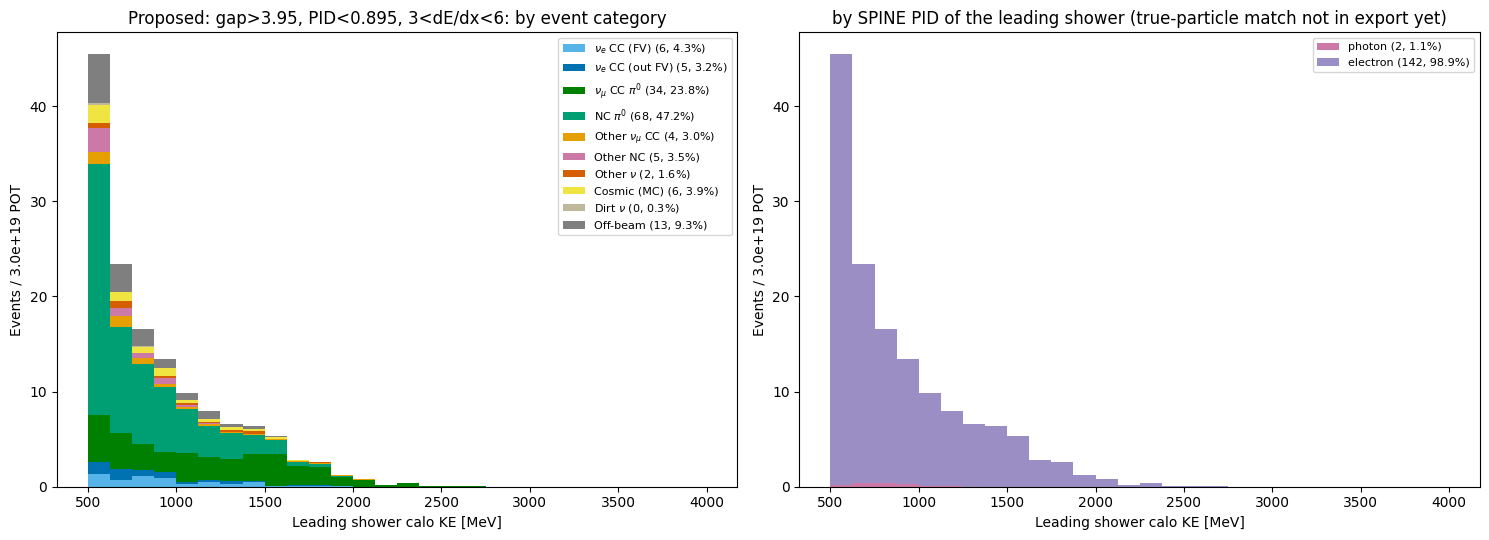

In [18]:
DISPLAY_POT = 3e19     # Lynn's first sideband request
def fig_sb_energy(name=SB_CHOICE, display_pot=DISPLAY_POT):
    d = PRED_T[in_sb(PRED_T, name)].copy()
    sc = display_pot / TARGET_POT
    bins = np.arange(KE_MIN, 4000 + 1, 125)
    fig, axes = plt.subplots(1, 2, figsize=(2 * STACK_FIGSIZE[0], STACK_FIGSIZE[1]))
    stacked(axes[0], d, 'sh_calo_ke', bins, scale=sc)
    axes[0].set_title(f'{name}: by event category')
    d['pidcat'] = d['sh_pid'].fillna(-1).astype(int)
    stacked(axes[1], d[d.pidcat >= 0], 'sh_calo_ke', bins, cat='pidcat', cats=PIDCAT, order=[0, 1, 2, 3, 4], scale=sc)
    axes[1].set_title('by SPINE PID of the leading shower (true-particle match not in export yet)')
    for ax in axes:
        ax.set_xlabel('Leading shower calo KE [MeV]')
        ax.set_ylabel(f'Events / {display_pot:.1e} POT')
        headroom(ax, 1.3); ax.legend(fontsize=DATAMC_LEGEND_FS, frameon=False)
    fig.tight_layout()
    savefig(fig, 'sideband_energy_' + re.sub(r'\W+', '_', name).strip('_'))
 
fig_sb_energy()


## 2.6 Signal contamination vs conversion-gap threshold (3 < dE/dx < 6 MeV/cm)

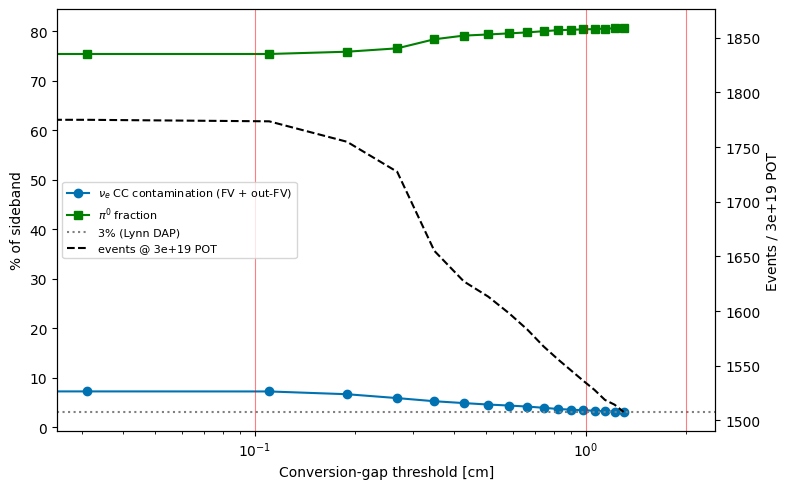

In [19]:
gaps = np.linspace(-1, 1.3, 30)
cont, nsb, pi0 = [], [], []
for g in gaps:
    d = PRED_T[box(PRED_T, g).fillna(False) & ~PRED_T[FINAL]]
    tot = d['w'].sum()
    cont.append(100 * d.loc[d.pcat.isin([0, 1]), 'w'].sum() / tot if tot else np.nan)
    pi0.append(100 * d.loc[d.pcat.isin([2, 3]), 'w'].sum() / tot if tot else np.nan)
    nsb.append(tot * DISPLAY_POT / TARGET_POT)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(gaps, cont, 'o-', color='#0072B2', label=r'$\nu_e$ CC contamination (FV + out-FV)')
ax.plot(gaps, pi0, 's-', color='green', label=r'$\pi^0$ fraction')
ax.axhline(3, color='gray', ls=':', label='3% (Lynn DAP)')
ax.set_xscale('log'); ax.set_xlabel('Conversion-gap threshold [cm]'); ax.set_ylabel('% of sideband')
ax2 = ax.twinx(); ax2.plot(gaps, nsb, 'k--', label=f'events @ {DISPLAY_POT:.0e} POT'); ax2.set_ylabel(f'Events / {DISPLAY_POT:.0e} POT')
for g in (0.1, 1, 2):
    ax.axvline(g, color='red', lw=0.8, alpha=0.5)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='center left')
fig.tight_layout(); savefig(fig, 'sideband_gap_scan')


## 2.7 Cut-flow efficiency and purity (Lynn TN Table 3 style, MC + dirt + off-beam at TARGET_POT)

In [20]:
def cutflow_table():
    den = meta.get('n_sig_truth_info') or meta['n_sig_presel']
    rows = []
    for s in [s for s in STAGES if s in set(CF.stage)]:
        c = CF[CF.stage == s]
        mc = c[c['sample'] == 'mc']
        sig_raw = mc.loc[mc.truth_cat == 0, 'n_raw'].sum()
        sig_w = mc.loc[mc.truth_cat == 0, 'n_w_target'].sum()
        tot_w = c.loc[c['sample'].isin(['mc', 'dirt', 'offbeam']), 'n_w_target'].sum()
        rows.append({'stage': s, 'efficiency %': 100 * sig_raw / den, 'purity %': 100 * sig_w / tot_w if tot_w else np.nan,
                     f'# νe CC @ {TARGET_POT:.1e}': sig_w, 'total pred.': tot_w,
                     'data (dev)': c.loc[c['sample'] == 'data', 'n_raw'].sum() if SHOW_DATA else np.nan})
    return pd.DataFrame(rows).set_index('stage')
 
CUTFLOW = cutflow_table()
CUTFLOW.to_csv(f'{PLOT_DIR}/cutflow_eff_pur.csv')
print(f"efficiency denominator: {'all true signal (truth_info)' if meta.get('n_sig_truth_info') else 'preselected true signal'}")
with pd.option_context('display.float_format', '{:.1f}'.format):
    display(CUTFLOW)
 
# ── Purity at the final stage: what is in the denominator ──────────────────────
fs = FINAL.replace('sel_', '')
c = CF[CF.stage == fs]
mcw = c[c['sample'] == 'mc'].groupby('truth_cat')['n_w_target'].sum()
comp = {name: mcw.get(k, 0.0) for k, name in
        [(0, 'νe CC FV (0)'), (1, 'νe CC out-FV (1)'), (2, 'νμ CC π0 (2)'), (3, 'NC π0 (3)'),
         (4, 'other νμ CC (4)'), (5, 'other NC (5)'), (6, 'other ν (6)'), (7, 'cosmic MC (7)')]}
comp['dirt'] = c.loc[c['sample'] == 'dirt', 'n_w_target'].sum()
comp['off-beam'] = c.loc[c['sample'] == 'offbeam', 'n_w_target'].sum()
comp = pd.Series(comp)
display(pd.DataFrame({f'events @ {TARGET_POT:.1e}': comp, '% of total': 100 * comp / comp.sum()}).round(1))
sig, b17 = comp.iloc[0], comp.iloc[1:8].sum()
print(f"purity νe/(MC cat 0–7)                        = {100*sig/(sig+b17):.1f}%   ← MC only")
print(f"purity νe/everything (MC + dirt ν + off-beam) = {100*sig/comp.sum():.1f}%   ← table above, comparable to Lynn's 80.1%")
 
# ── Who are the 'other ν' (cat 6) events? ────────────────────────────────────────
mc7 = EV['mc'][(EV['mc']['truth_cat'] == 6) & EV['mc'][FINAL]]
print(f"\nother ν (cat 6) at {fs}: {len(mc7)} raw MC events")
for col in ['ti_is_nu', 'ti_mct_index', 'ti_is_true_signal', 'ti_is_cc', 'ti_is_fv_true',
            'ti_has_true_electron', 'ti_has_pi0']:
    if col in mc7.columns:
        vc = mc7[col].value_counts(dropna=False).head(6)
        print(f"  {col:<22s} NaN={mc7[col].isna().mean():.0%}  " + ', '.join(f'{k}:{v}' for k, v in vc.items()))


efficiency denominator: all true signal (truth_info)


,efficiency %,purity %,# νe CC @ 6.6e+20,total pred.,data (dev)
stage,,,,,
precut,96.5,0.3,13094.3,4754677.8,39225
valid_flashmatch,96.5,0.3,13094.3,4754677.8,39225
fiducial,96.5,0.3,13094.3,4754677.8,39225
single_electron,87.7,37.8,11893.9,31456.2,206
electron_primary_score,84.5,40.4,11465.6,28351.3,190
electron_pid_score,73.1,59.2,9915.5,16737.9,114
vertex_distance,67.4,67.3,9146.9,13594.5,91
start_dedx,40.1,87.2,5437.7,6234.6,35


,events @ 6.6e+20,% of total
νe CC FV (0),5437.7,87.2
νe CC out-FV (1),62.2,1.0
νμ CC π0 (2),227.6,3.7
NC π0 (3),150.2,2.4
other νμ CC (4),36.4,0.6
other NC (5),25.8,0.4
other ν (6),61.0,1.0
cosmic MC (7),58.7,0.9
dirt,0.0,0.0
off-beam,175.1,2.8


purity νe/(MC cat 0–7)                        = 89.7%   ← MC only
purity νe/everything (MC + dirt ν + off-beam) = 87.2%   ← table above, comparable to Lynn's 80.1%

other ν (cat 6) at start_dedx: 52 raw MC events
  ti_is_nu               NaN=0%  True:52
  ti_mct_index           NaN=0%  0:30, 1:17, 2:4, 4:1
  ti_is_true_signal      NaN=0%  False:52
  ti_is_cc               NaN=0%  True:52
  ti_is_fv_true          NaN=0%  True:51, False:1
  ti_has_true_electron   NaN=0%  False:52
  ti_has_pi0             NaN=0%  False:30, True:22


## 2.8 True interaction mode: signal / background in signal region / sideband (Lynn TN Fig. 24 style)
Needs `ti_` columns with a mode and a true Eν; prints the available `ti_` columns otherwise.

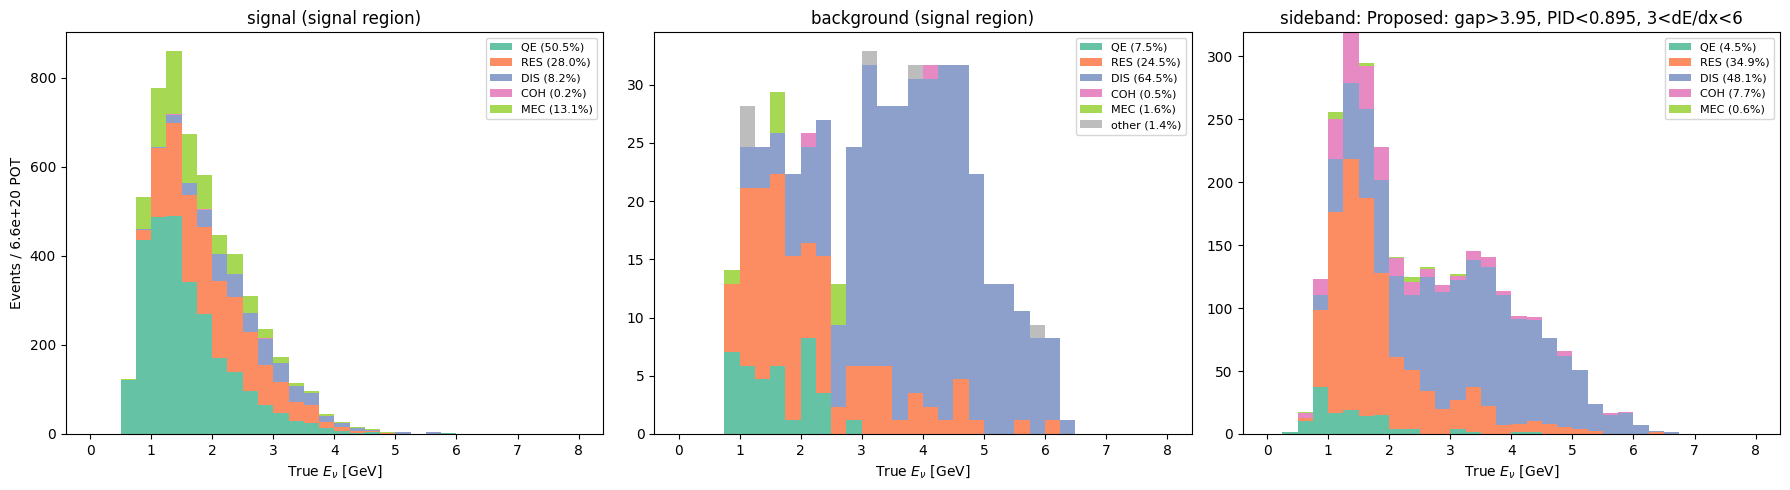

In [21]:
ti_cols = [c for c in EV['mc'].columns if c.startswith('ti_')]
MODE_COL = next((c for c in ti_cols if 'mode' in c.lower()), None)
ENU_COL  = next((c for c in ti_cols if c.lower() in ('ti_e', 'ti_nu_e', 'ti_enu', 'ti_nu_energy', 'ti_true_e', 'ti_true_nu_e')), None)
MODE_NAMES = {0: 'QE', 1: 'RES', 2: 'DIS', 3: 'COH', 10: 'MEC'}
MODE_COLS = {'QE': '#66c2a5', 'RES': '#fc8d62', 'DIS': '#8da0cb', 'COH': '#e78ac3', 'MEC': '#a6d854', 'other': '#bdbdbd'}
 
if MODE_COL is None or ENU_COL is None:
    print('mode / Eν columns not found among ti_ columns:', ti_cols)
    print('→ set MODE_COL / ENU_COL by hand (or add them to truth_info in make_nueCC_df).')
else:
    mc = PRED_T[PRED_T['sample'] == 'mc'].copy()
    mc['mode'] = mc[MODE_COL].map(MODE_NAMES).fillna('other')
    regions = [('signal (signal region)', mc[FINAL] & (mc.pcat == 0)),
               ('background (signal region)', mc[FINAL] & mc.pcat.between(1, 5)),
               (f'sideband: {SB_CHOICE}', in_sb(mc, SB_CHOICE))]
    bins = np.linspace(0, 8, 33)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (t, m) in zip(axes, regions):
        d = mc[m]
        bottom = np.zeros(len(bins) - 1)
        for mode, col in MODE_COLS.items():
            mm = d['mode'] == mode
            h, _ = np.histogram(d.loc[mm, ENU_COL], bins=bins, weights=d.loc[mm, 'w'])
            if h.sum() > 0:
                ax.bar(bins[:-1], h, np.diff(bins), bottom=bottom, align='edge', color=col,
                       label=f'{mode} ({100*h.sum()/d.w.sum():.1f}%)')
                bottom += h
        ax.set_title(t); ax.set_xlabel(r'True $E_\nu$ [GeV]'); ax.legend(fontsize=8)
    axes[0].set_ylabel(f'Events / {TARGET_POT:.1e} POT')
    fig.tight_layout(); savefig(fig, 'interaction_mode_breakdown')


## 2.9 Data checks (Gen1 dev sample only): time stability and sideband data/MC

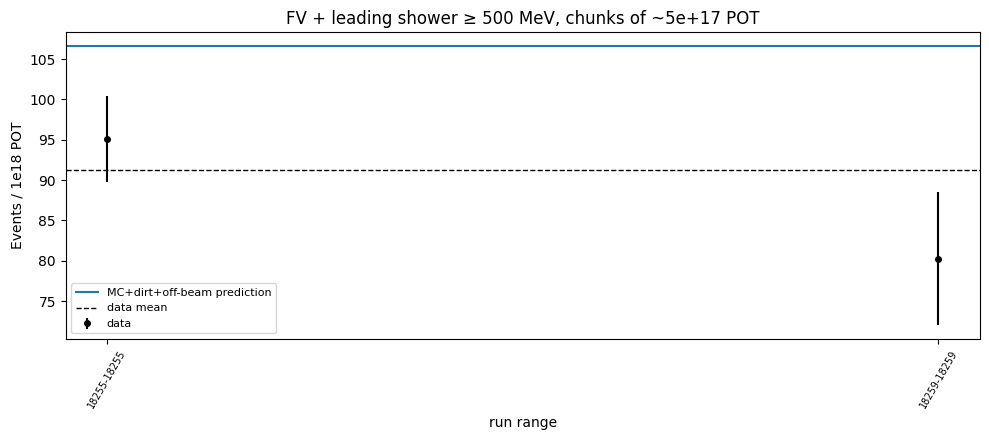

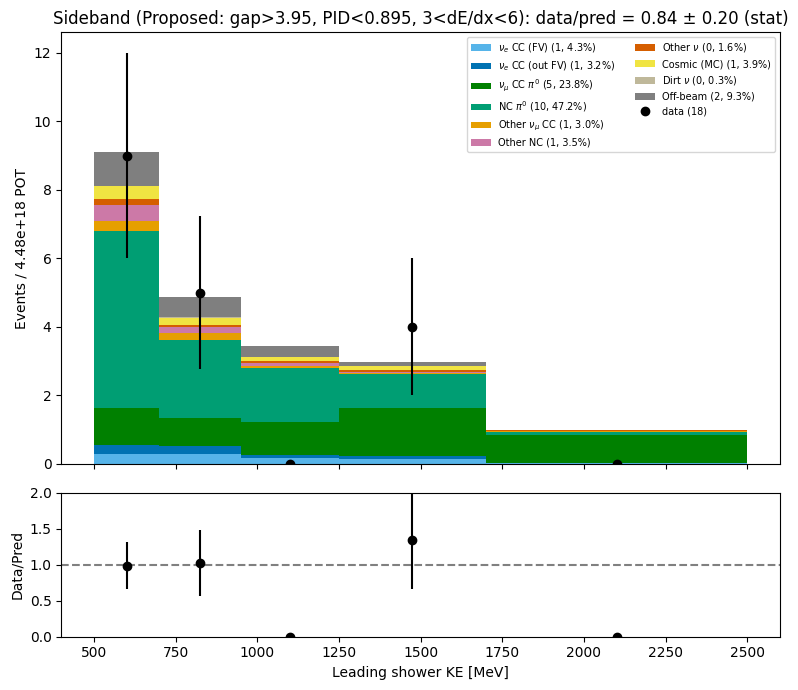

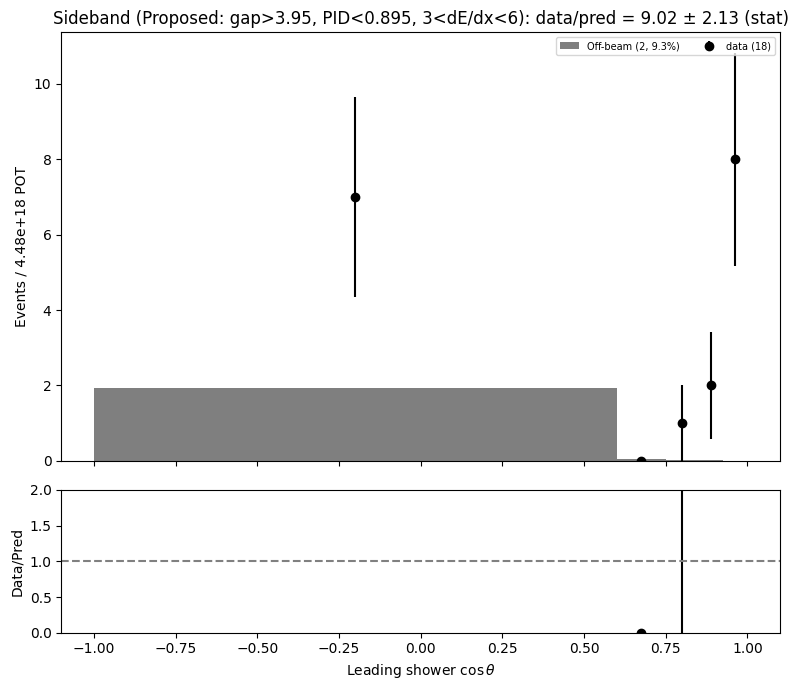

In [22]:
if not SHOW_DATA:
    print('data not shown (no data CSV, or production is not Gen1)')
else:
    # time stability: FV + leading shower ≥ KE_MIN, per run chunk, normalized per 1e18 POT
    if os.path.exists(f'{CSV_DIR}/data_pot_by_run.csv'):
        pbr = pd.read_csv(f'{CSV_DIR}/data_pot_by_run.csv').sort_values('run')
        CHUNK_POT = 5e17
        pbr['chunk'] = (pbr['pot'].cumsum() // CHUNK_POT).astype(int)
        chunks = pbr.groupby('chunk').agg(run_lo=('run', 'min'), run_hi=('run', 'max'), pot=('pot', 'sum'))
        n = DATA[SHOWER(DATA)].groupby('run').size()
        pbr['n'] = pbr['run'].map(n).fillna(0)
        chunks['n'] = pbr.groupby('chunk')['n'].sum()
        rate, err = chunks.n / chunks.pot * 1e18, np.sqrt(chunks.n) / chunks.pot * 1e18
        pred = PRED_D.loc[SHOWER(PRED_D).fillna(False), 'w'].sum() / DATA_POT * 1e18
        fig, ax = plt.subplots(figsize=(10, 4.5))
        ax.errorbar(np.arange(len(chunks)), rate, err, fmt='ko', ms=4, label='data')
        ax.axhline(pred, color='C0', label='MC+dirt+off-beam prediction')
        ax.axhline(chunks.n.sum() / chunks.pot.sum() * 1e18, color='k', ls='--', lw=1, label='data mean')
        ax.set_xticks(np.arange(len(chunks)))
        ax.set_xticklabels([f'{a}-{b}' for a, b in zip(chunks.run_lo, chunks.run_hi)], rotation=60, fontsize=7)
        ax.set_ylabel('Events / 1e18 POT'); ax.set_xlabel('run range')
        ax.set_title(f'FV + leading shower ≥ {KE_MIN:g} MeV, chunks of ~{CHUNK_POT:.0e} POT')
        ax.legend(fontsize=8); fig.tight_layout(); savefig(fig, 'data_time_stability')
 
    # sideband data/MC in the chosen definition
    for var, bins, xl in [('sh_calo_ke', np.array([500, 700, 950, 1250, 1700, 2500]), 'Leading shower KE [MeV]'),
                          ('sh_costheta', np.array([-1, 0.6, 0.75, 0.85, 0.925, 1.0]), r'Leading shower $\cos\theta$')]:
        d = PRED_D[in_sb(PRED_D, SB_CHOICE)]
        x = DATA.loc[in_sb(DATA, SB_CHOICE), var].clip(bins[0], bins[-1] - 1e-9)
        fig, (ax, ar) = plt.subplots(2, 1, figsize=DATAMC_FIGSIZE, sharex=True, gridspec_kw={'height_ratios': [3.2, 1]})
        tot = stacked(ax, d, var, bins)
        dc, _ = np.histogram(x, bins=bins)
        c = 0.5 * (bins[1:] + bins[:-1])
        ax.errorbar(c, dc, np.sqrt(dc), fmt='ko', label=f'data ({dc.sum()})')
        ax.set_ylabel(f'Events / {DATA_POT:.2e} POT'); headroom(ax); ax.legend(fontsize=DATAMC_LEGEND_FS, ncol=2, frameon=False)
        ax.set_title(f'Sideband ({SB_CHOICE}): data/pred = {dc.sum()/tot.sum():.2f} ± {np.sqrt(dc.sum())/tot.sum():.2f} (stat)')
        with np.errstate(divide='ignore', invalid='ignore'):
            ar.errorbar(c, dc / tot, np.sqrt(dc) / tot, fmt='ko')
        ar.axhline(1, color='gray', ls='--'); ar.set_ylim(0, 2); ar.set_ylabel('Data/Pred'); ar.set_xlabel(xl)
        fig.tight_layout(); savefig(fig, f'sideband_datamc_{var}')


### 2.9b Data-driven data-access plan
How much POT each unblinding stage needs, from the dev-sample sideband rate (data-driven normalization), the
per-bin systematics of nue_syst.ipynb and the predicted signal-region yields (the signal region stays blind for
sizing). Requirements and Run-1 POT are set at the top of the cell; the stage table is saved to
`plots_analysis/data_access_plan.csv`.

systematics from ./saved_syst/reco_ke/total_cov_matrices.npz
  background uncertainty per bin [%]: [22.4 26.7 24.4 23.1 22.1 28.3]
  total uncertainty per bin      [%]: [ 7.8  8.2  8.4  9.1 11.3 14.9]

Sideband: Proposed: gap>3.95, PID<0.895, 3<dE/dx<6
  dev sample (4.48e+18 POT): data 18.0  pred 21.4  → r = data/pred = 0.841 ± 0.198 (stat)
  ν_e (CC, in + out FV) contamination of the sideband (MC): 7.4%   ⚠ > 5%: opening the sideband also shows ν_e events — say so in the request
  (A) per-bin stat ≤ 0.5×bkg syst  → 2.57e+21 POT   (per bin: 4.1e+19, 6.0e+19, 1.3e+20, 1.6e+20, 7.6e+20, 2.6e+21)
      integrated sideband (mean bkg syst 24%) → 1.76e+19 POT
      ⚠ per-bin requirement needs 10.3× Run 1 → stage 2 uses the integrated sideband; per-bin constraint only with coarser high-KE bins or the full sideband at stage 4
  (B) see the dev deviation |r−1| = 0.16 at 3σ → 6.28e+19 POT;   resolve a 10% deviation at 3σ → 1.58e+20 POT

Signal region (prediction): 945 selected / 1e20 POT, 824 ν_

,POT,% of Run 1,sideband events (data-driven),sideband worst-bin stat %,ν_e in sideband,SR selected (pred),SR ν_e CC (pred),SR worst-bin stat %,# 1e+19 slices,criterion
stage,,,,,,,,,,
1 dev sample (now),4.48e+18,1.79,18,339,1.34,42.3,36.9,53,0.448,selection development; all variables; area- then POT-normalized
2 sideband only,3e+19,12,121,131,8.97,283,247,20.5,3,(A) integrated (per-bin > Run 1): sideband stat ≤ 0.5× bkg syst
"3 signal region, partial",7.5e+19,30,302,82.8,22.4,708,618,13,7.5,(C) per-bin stat ≤ 1× syst (≤ 30% of Run 1); time slices ≤ 1e+19 POT
4 full Run 1,2.5e+20,100,1.01e+03,45.4,74.8,2.36e+03,2.06e+03,7.09,25,"frozen selection, sidebands, systematics; fake-data tests passed"


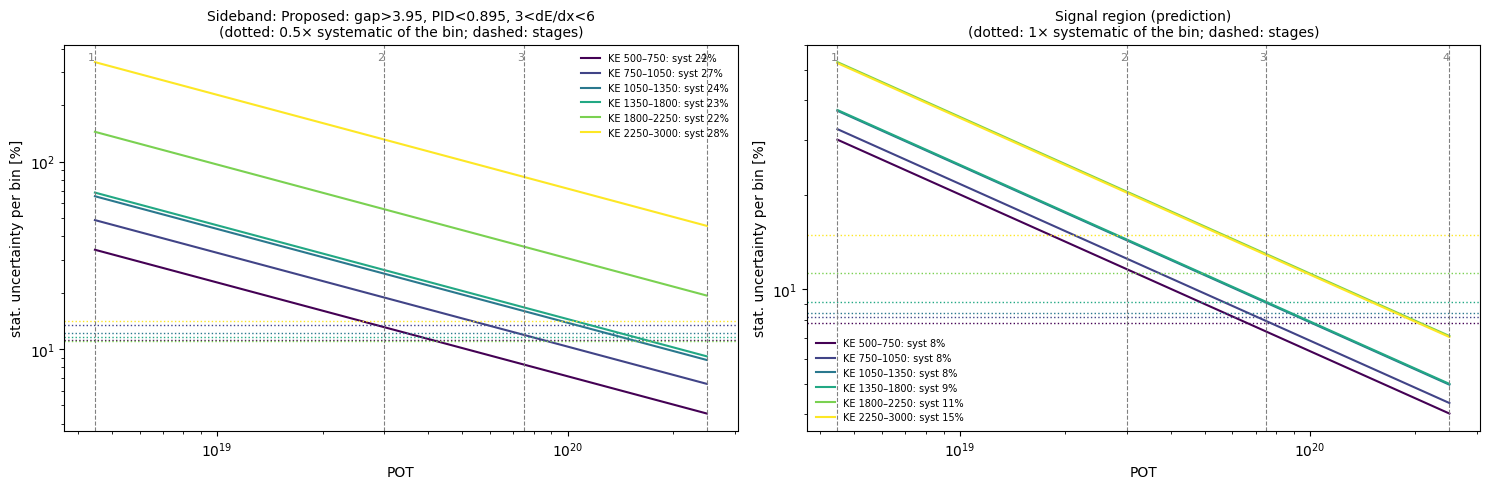

In [23]:
# §2.9b — Data-driven data-access plan: how much POT does each unblinding stage need?
# Inputs measured or predicted here (nothing hand-set except the requirements below):
#   • sideband (SB_CHOICE, built from the nue_selection thresholds): dev-sample data rate per POT and
#     data/pred normalization r; per-bin background-model uncertainty from saved_syst (nue_syst.ipynb)
#   • signal region: PREDICTION only (still blind — the dev-sample signal data are not used for sizing)
# Requirements:
#   (A) sideband constraint: per-bin data stat. error ≤ SB_STAT_FRAC × background uncertainty of that bin
#   (B) sideband normalization: POT to see the dev-sample deviation |r − 1| at N_SIGMA, and to resolve a
#       10% deviation at N_SIGMA
#   (C) signal region: per-bin stat. error ≤ SIG_STAT_FRAC × total systematic of that bin
#   (D) time slices: preselection-level plots (FV + leading shower ≥ KE_MIN) with ≤ SLICE_POT each
RUN1_POT      = 2.5e20     # Run-1 total available (M. Carrigan DAP 2.5e20; L. Tung DAP 3e20) — set to the approved number
SLICE_POT     = 1e19       # max POT per pre-electron-selection plot (keeps the ν_μ analyses blind)
SB_STAT_FRAC  = 0.5        # (A)
SIG_STAT_FRAC = 1.0        # (C)
N_SIGMA       = 3.0        # (B)
KE_BINS       = np.array([500., 750., 1050., 1350., 1800., 2250., 3000.])   # nue_xsec reco_ke bins
KE_VAR        = EP + 'ke'                                                    # selection electron KE
SYST_NPZ      = './saved_syst/reco_ke/total_cov_matrices.npz'
STEPS         = np.array([1e19, 3e19, 5e19, 1e20, 1.5e20, 2e20])             # request granularity


def _hist(d, mask=None, w=True):
    d = d if mask is None else d[mask]
    x = d[KE_VAR].clip(KE_BINS[0], KE_BINS[-1] - 1e-9)
    return np.histogram(x, bins=KE_BINS, weights=d['w'] if w else None)[0].astype(float)


def _step_up(p):
    """Smallest request step ≥ p (or Run 1)."""
    if not np.isfinite(p):
        return np.nan
    s = STEPS[STEPS >= p]
    return float(s[0]) if len(s) and s[0] < RUN1_POT else RUN1_POT


# ── systematic levels per KE bin (fractional), from nue_syst.ipynb ───────────────────────────────
if os.path.exists(SYST_NPZ):
    _z = np.load(SYST_NPZ)
    with np.errstate(divide='ignore', invalid='ignore'):
        FRAC_BKG = np.sqrt(np.diag(_z['total_cov_bs_bs'])) / _z['bs']
        FRAC_TOT = np.sqrt(np.diag(_z['total_cov_ms_ms']) + np.diag(_z['total_cov_bs_bs'])) / (_z['ms'] + _z['bs'])
    assert len(FRAC_BKG) == len(KE_BINS) - 1, f'{SYST_NPZ} has {len(FRAC_BKG)} bins, KE_BINS {len(KE_BINS) - 1}'
    _syst_src = SYST_NPZ
else:
    FRAC_BKG, FRAC_TOT = np.full(len(KE_BINS) - 1, 0.20), np.full(len(KE_BINS) - 1, 0.10)
    _syst_src = 'defaults (20% bkg, 10% total) — run nue_syst.ipynb for the real values'
print(f'systematics from {_syst_src}')
print('  background uncertainty per bin [%]:', np.round(100 * FRAC_BKG, 1))
print('  total uncertainty per bin      [%]:', np.round(100 * FRAC_TOT, 1))

# ── sideband (data-driven) ───────────────────────────────────────────────────────────────────────
sb_p = in_sb(PRED_D, SB_CHOICE)
SB_PRED = _hist(PRED_D, sb_p)                                         # at DATA_POT
SB_NUE  = PRED_D.loc[sb_p & PRED_D['pcat'].isin([0, 1]), 'w'].sum() / max(SB_PRED.sum(), 1e-9)
if SHOW_DATA:
    SB_DATA = _hist(DATA, in_sb(DATA, SB_CHOICE), w=False)
    r_sb, e_sb = SB_DATA.sum() / SB_PRED.sum(), np.sqrt(max(SB_DATA.sum(), 1)) / SB_PRED.sum()
else:
    SB_DATA, r_sb, e_sb = None, 1.0, np.nan
sb_rate = r_sb * SB_PRED / DATA_POT                                   # expected data events per POT per bin
with np.errstate(divide='ignore', invalid='ignore'):
    P_A_bin = 1.0 / (SB_STAT_FRAC ** 2 * FRAC_BKG ** 2 * sb_rate)
P_A = float(np.nanmax(np.where(SB_PRED > 0, P_A_bin, np.nan)))
# integrated sideband (one bin; event-weighted mean background uncertainty) — the fallback when the
# per-bin requirement cannot be met within Run 1 (high-KE bins are nearly empty)
_fb = np.sum(FRAC_BKG * SB_PRED) / max(SB_PRED.sum(), 1e-9)
P_A_tot = 1.0 / (SB_STAT_FRAC ** 2 * _fb ** 2 * sb_rate.sum())
P_B = DATA_POT * (N_SIGMA * e_sb / abs(r_sb - 1)) ** 2 if SHOW_DATA and abs(r_sb - 1) > 0 else np.nan
P_B10 = DATA_POT * (N_SIGMA * e_sb / 0.10) ** 2 if SHOW_DATA else np.nan

print(f'\nSideband: {SB_CHOICE}')
print(f'  dev sample ({DATA_POT:.2e} POT): data {SB_DATA.sum() if SB_DATA is not None else "—"}  '
      f'pred {SB_PRED.sum():.1f}  → r = data/pred = {r_sb:.3f} ± {e_sb:.3f} (stat)')
print(f'  ν_e (CC, in + out FV) contamination of the sideband (MC): {100 * SB_NUE:.1f}%'
      + ('   ⚠ > 5%: opening the sideband also shows ν_e events — say so in the request' if SB_NUE > 0.05 else ''))
print(f'  (A) per-bin stat ≤ {SB_STAT_FRAC:g}×bkg syst  → {P_A:.2e} POT   (per bin: '
      + ', '.join(f'{p:.1e}' for p in P_A_bin) + ')')
print(f'      integrated sideband (mean bkg syst {100 * _fb:.0f}%) → {P_A_tot:.2e} POT')
if P_A > RUN1_POT:
    print(f'      ⚠ per-bin requirement needs {P_A / RUN1_POT:.1f}× Run 1 → stage 2 uses the integrated sideband; '
          'per-bin constraint only with coarser high-KE bins or the full sideband at stage 4')
if SHOW_DATA:
    print(f'  (B) see the dev deviation |r−1| = {abs(r_sb - 1):.2f} at {N_SIGMA:g}σ → {P_B:.2e} POT;   '
          f'resolve a 10% deviation at {N_SIGMA:g}σ → {P_B10:.2e} POT')

# ── signal region (prediction only) ──────────────────────────────────────────────────────────────
fin = PRED_D[FINAL]
SR_TOT, SR_SIG = _hist(PRED_D, PRED_D[FINAL]), _hist(PRED_D, PRED_D[FINAL] & (PRED_D['pcat'] == 0))
sr_rate = SR_TOT / DATA_POT
with np.errstate(divide='ignore', invalid='ignore'):
    P_C_bin = 1.0 / (SIG_STAT_FRAC ** 2 * FRAC_TOT ** 2 * sr_rate)
P_C = float(np.nanmax(np.where(SR_TOT > 0, P_C_bin, np.nan)))
print(f'\nSignal region (prediction): {SR_TOT.sum() / DATA_POT * 1e20:.0f} selected / 1e20 POT, '
      f'{SR_SIG.sum() / DATA_POT * 1e20:.0f} ν_e CC (purity {SR_SIG.sum() / SR_TOT.sum():.2f})')
print(f'  (C) per-bin stat ≤ {SIG_STAT_FRAC:g}×total syst → {P_C:.2e} POT   (per bin: '
      + ', '.join(f'{p:.1e}' for p in P_C_bin) + ')')

# ── time slices (preselection level) ─────────────────────────────────────────────────────────────
pre = PRED_D['sel_fiducial'] & SHOWER(PRED_D).fillna(False)
pre_rate = PRED_D.loc[pre, 'w'].sum() / DATA_POT
if SHOW_DATA:
    d_pre = (DATA['sel_fiducial'] & SHOWER(DATA).fillna(False)).sum()
    pre_rate_d = d_pre / DATA_POT
else:
    pre_rate_d = pre_rate
print(f'\n(D) preselection (FV + shower ≥ {KE_MIN:g} MeV): {pre_rate_d * SLICE_POT:.0f} data events per '
      f'{SLICE_POT:.0e}-POT slice → ±{100 / np.sqrt(pre_rate_d * SLICE_POT):.1f}% rate per slice')

# ── stage table ──────────────────────────────────────────────────────────────────────────────────
SB_PER_BIN = P_A <= RUN1_POT
P_SB  = _step_up(P_A if SB_PER_BIN else P_A_tot)
P_SR1 = min(_step_up(P_C), 0.3 * RUN1_POT) if np.isfinite(P_C) else 0.3 * RUN1_POT
STAGES_ACCESS = [
    ('1  dev sample (now)',                 DATA_POT, 'selection development; all variables; area- then POT-normalized'),
    ('2  sideband only',                    P_SB,     f'(A) {"per bin" if SB_PER_BIN else "integrated (per-bin > Run 1)"}: '
                                                      f'sideband stat ≤ {SB_STAT_FRAC:g}× bkg syst'),
    ('3  signal region, partial',           P_SR1,    f'(C) per-bin stat ≤ {SIG_STAT_FRAC:g}× syst (≤ 30% of Run 1); '
                                                      f'time slices ≤ {SLICE_POT:.0e} POT'),
    ('4  full Run 1',                       RUN1_POT, 'frozen selection, sidebands, systematics; fake-data tests passed'),
]
rows = []
for name, P, why in STAGES_ACCESS:
    k = P / DATA_POT
    rows.append({'stage': name, 'POT': P, '% of Run 1': 100 * P / RUN1_POT,
                 'sideband events (data-driven)': r_sb * SB_PRED.sum() * k,
                 'sideband worst-bin stat %': 100 * np.nanmax(1 / np.sqrt(np.where(SB_PRED > 0, r_sb * SB_PRED * k, np.nan))),
                 'ν_e in sideband': SB_NUE * r_sb * SB_PRED.sum() * k,
                 'SR selected (pred)': SR_TOT.sum() * k, 'SR ν_e CC (pred)': SR_SIG.sum() * k,
                 'SR worst-bin stat %': 100 * np.nanmax(1 / np.sqrt(np.where(SR_TOT > 0, SR_TOT * k, np.nan))),
                 f'# {SLICE_POT:.0e} slices': P / SLICE_POT, 'criterion': why})
ACCESS_TABLE = pd.DataFrame(rows).set_index('stage')
ACCESS_TABLE.to_csv(f'{PLOT_DIR}/data_access_plan.csv')
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.width', 250, 'display.max_colwidth', 80):
    display(ACCESS_TABLE)

# ── figure: stat precision vs POT ────────────────────────────────────────────────────────────────
pots = np.logspace(np.log10(DATA_POT), np.log10(RUN1_POT), 200)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 5))
for ax, hist, frac, fac, title in [(a0, r_sb * SB_PRED, FRAC_BKG, SB_STAT_FRAC, f'Sideband: {SB_CHOICE}'),
                                   (a1, SR_TOT, FRAC_TOT, SIG_STAT_FRAC, 'Signal region (prediction)')]:
    for b in range(len(hist)):
        if hist[b] <= 0:
            continue
        col = plt.cm.viridis(b / max(len(hist) - 1, 1))
        ax.plot(pots, 100 / np.sqrt(hist[b] * pots / DATA_POT), color=col,
                label=f'KE {KE_BINS[b]:g}–{KE_BINS[b + 1]:g}: syst {100 * frac[b]:.0f}%')
        ax.axhline(100 * fac * frac[b], color=col, ls=':', lw=1)
    for name, P, _ in STAGES_ACCESS:
        ax.axvline(P, color='gray', ls='--', lw=0.8)
        ax.text(P, 0.98, name.split()[0], transform=ax.get_xaxis_transform(), ha='right', va='top', fontsize=8, color='gray')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('POT'); ax.set_ylabel('stat. uncertainty per bin [%]')
    ax.set_title(title + f'\n(dotted: {fac:g}× systematic of the bin; dashed: stages)', fontsize=10)
    ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); savefig(fig, 'data_access_plan')


## 2.10 Event lists for scanning in spinal-tap
Writes `saved_csvs/scan_lists/<name>.csv` (run, subrun, evt first). Feed a list to `find_events_h5.py`, which
returns the SPINE HDF5 file and entry for each event (what spinal-tap needs). Add your own masks at the end.

In [24]:
SCAN_DIR = f'{CSV_DIR}/scan_lists'
os.makedirs(SCAN_DIR, exist_ok=True)
SCAN_VARS = ['sh_calo_ke', 'sh_pid', 'sh_start_dedx', 'sh_vertex_distance', 'sh_costheta',
             'e_calo_ke', 'e_start_dedx', 'e_vertex_distance', 'e_pid_score_electron', 'e_primary_score',
             'n_photon_primary', 'n_electron_primary', 'n_muon_primary', 'n_proton_primary',
             'trk_length', 'vtx_x', 'vtx_y', 'vtx_z', 'ana_reco_ke', 'ana_reco_costheta']
 
 
def scan_list(df, mask, name):
    mask = pd.Series(mask, index=df.index).fillna(False).astype(bool)
    cols = [c for c in META_COLS + SCAN_VARS + [c for c in df.columns if c.startswith('sel_')] if c in df.columns]
    out = df.loc[mask, cols].sort_values([c for c in ('run', 'subrun', 'evt') if c in cols])
    out.to_csv(f'{SCAN_DIR}/{name}.csv', index=False)
    print(f'{name:<34s} {len(out):>5d} events → {SCAN_DIR}/{name}.csv')
    return out
 
 
if SHOW_DATA:
    scan_list(DATA, DATA[FINAL], 'data_final')
    scan_list(DATA, in_sb(DATA, SB_CHOICE), 'data_sideband')
    scan_list(DATA, DATA['sel_single_electron'] & ~DATA[FINAL], 'data_topology_failed_final')
    # example of a bin you want to look at: highest-KE bin at the final stage
    scan_list(DATA, DATA[FINAL] & (DATA['e_calo_ke'] >= 2200), 'data_final_ke_ge_2200')
scan_list(EV['mc'], (EV['mc']['truth_cat'] == 6) & EV['mc'][FINAL], 'mc_other_nu_final')
scan_list(EV['mc'], (EV['mc']['truth_cat'].isin([2, 3])) & EV['mc'][FINAL], 'mc_pi0_bkg_final')


data_final                            35 events → ./saved_csvs/scan_lists/data_final.csv
data_sideband                         18 events → ./saved_csvs/scan_lists/data_sideband.csv
data_topology_failed_final           171 events → ./saved_csvs/scan_lists/data_topology_failed_final.csv
data_final_ke_ge_2200                  3 events → ./saved_csvs/scan_lists/data_final_ke_ge_2200.csv
mc_other_nu_final                     52 events → ./saved_csvs/scan_lists/mc_other_nu_final.csv
mc_pi0_bkg_final                     322 events → ./saved_csvs/scan_lists/mc_pi0_bkg_final.csv


,run,subrun,evt,sample,truth_cat,idx0,idx1,idx2,int_id,sh_id,...,ana_reco_ke,ana_reco_costheta,sel_precut,sel_valid_flashmatch,sel_fiducial,sel_single_electron,sel_electron_primary_score,sel_electron_pid_score,sel_vertex_distance,sel_start_dedx
33097,52,55,24,mc,3,224309,3,1,1.0,1.0,...,2007.38550,0.945044,True,True,True,True,True,True,True,True
30918,73,32,39,mc,3,209360,4,3,3.0,6.0,...,716.49005,0.796395,True,True,True,True,True,True,True,True
38965,117,82,6,mc,2,263562,1,5,5.0,9.0,...,1678.42570,0.987290,True,True,True,True,True,True,True,True
8709,118,22,89,mc,2,57978,17,1,1.0,1.0,...,2266.37100,0.910363,True,True,True,True,True,True,True,True
9511,118,56,38,mc,2,63585,6,3,3.0,5.0,...,2559.17260,0.986677,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38397,4329,93,92,mc,2,259750,17,5,5.0,7.0,...,3009.42200,0.989174,True,True,True,True,True,True,True,True
11392,4335,80,42,mc,2,76596,11,0,0.0,3.0,...,2773.62480,0.998801,True,True,True,True,True,True,True,True
13094,4395,94,47,mc,3,87830,6,1,1.0,2.0,...,1289.68490,0.899024,True,True,True,True,True,True,True,True
5894,4405,99,20,mc,2,39229,3,0,0.0,0.0,...,776.97370,0.981912,True,True,True,True,True,True,True,True


## 2.11 Data/MC mismatch finder → event lists ready for spinal-tap 
For each variable, histogram data vs prediction (MC incl. cat 7 + dirt + off-beam) at the stage
just BEFORE that variable is cut on (N-1 style), flag bins whose Poisson p-value < P_FLAG, and
write the data events in flagged bins (with h5_file / h5_entry) to scan_lists/mismatch/.
Deficit bins: data has too FEW events, so there is nothing missing to look at in data — the
list of over-predicted MC events (same bin) is written instead, for the MC SPINE files.

In [25]:
from math import lgamma, log, exp

H5_INDEX   = '/exp/sbnd/app/users/castalyf/h5_index_bnblight_dev.csv'   # built by find_events_h5.py
SHAPE_ONLY = True     # scale prediction to the data total first (the ~0.84 normalization is known)
P_FLAG     = 0.05     # flag bins with Poisson p below this
MIS_DIR    = f'{CSV_DIR}/scan_lists/mismatch'
os.makedirs(MIS_DIR, exist_ok=True)

CHECKS = [  # (variable, events must pass this stage, bin edges) — the stage is the cut BEFORE the variable's cut
    ('e_primary_score',      'sel_single_electron',        np.linspace(0, 1, 11)),
    ('e_pid_score_electron', 'sel_electron_primary_score', np.linspace(0, 1, 11)),
    ('e_vertex_distance',    'sel_electron_pid_score',     np.array([0, 0.25, 0.5, 1, 2, 3, 5, 10, 30])),
    ('e_start_dedx',         'sel_vertex_distance',        np.array([0, 1, 1.5, 2, 2.5, 3, 4, 6, 10])),
    ('e_calo_ke',            FINAL,                        np.array([500, 700, 1000, 1300, 1700, 2200, 3000])),
    ('sh_costheta',          FINAL,                        np.array([-1, 0.6, 0.75, 0.85, 0.925, 1.0])),
    ('vtx_x',                FINAL,                        np.linspace(-200, 200, 9)),
    ('vtx_z',                FINAL,                        np.linspace(0, 500, 11)),
]


PLAIN = {0: 'nueCC-FV', 1: 'nueCC-outFV', 2: 'numuCCpi0', 3: 'NCpi0', 4: 'numuCC-other', 5: 'NC-other',
         6: 'otherNu', 7: 'cosmicMC', 8: 'offbeam', 9: 'dirt'}


def _pois_cdf(k, mu):                       # P(N <= k | mu)
    if mu <= 0:
        return 1.0
    return min(1.0, sum(exp(i * log(mu) - mu - lgamma(i + 1)) for i in range(int(k) + 1)))


def _pvalue(n, mu):                         # one-sided, in the direction of the deviation
    return 1.0 - _pois_cdf(n - 1, mu) if n > mu else _pois_cdf(n, mu)


_h5 = None
if os.path.exists(H5_INDEX):
    _h5 = pd.read_csv(H5_INDEX).rename(columns={'file': 'h5_file', 'entry': 'h5_entry', 'event': 'evt'})
else:
    print(f'h5 index not found at {H5_INDEX} → lists will have run/subrun/evt only')


def _locate(df):
    if _h5 is None or df.empty or not {'run', 'subrun', 'evt'} <= set(df.columns):
        return df
    k = ['run', 'subrun', 'evt']
    m = df.merge(_h5[k + ['h5_file', 'h5_entry']].drop_duplicates(k), on=k, how='left')
    return m[['h5_file', 'h5_entry'] + [c for c in m.columns if c not in ('h5_file', 'h5_entry')]]


def mismatch(var, stage, bins, shape_only=SHAPE_ONLY, p_flag=P_FLAG, show=True):
    pm = SHOWER(PRED_D).fillna(False) & PRED_D[stage]
    dm = SHOWER(DATA).fillna(False) & DATA[stage]
    p, d = PRED_D[pm], DATA[dm]
    clip = lambda s: s.clip(bins[0], bins[-1] - 1e-9)
    pb = np.digitize(clip(p[var]), bins) - 1
    db = np.digitize(clip(d[var]), bins) - 1
    mu = np.bincount(pb[p[var].notna()], weights=p.loc[p[var].notna(), 'w'], minlength=len(bins) - 1)
    n = np.bincount(db[d[var].notna()], minlength=len(bins) - 1).astype(float)
    norm = n.sum() / mu.sum() if (shape_only and mu.sum() > 0) else 1.0
    mu = mu * norm
    rows = []
    for i in range(len(bins) - 1):
        comp = p[pb == i].groupby('pcat')['w'].sum().sort_values(ascending=False) * norm
        top = ', '.join(f'{PLAIN.get(c, c)} {v:.1f}' for c, v in comp.head(3).items())
        rows.append(dict(bin=f'[{bins[i]:g}, {bins[i+1]:g})', data=int(n[i]), pred=mu[i],
                         ratio=n[i] / mu[i] if mu[i] > 0 else np.nan,
                         pull=(n[i] - mu[i]) / np.sqrt(mu[i]) if mu[i] > 0 else np.nan,
                         p=_pvalue(n[i], mu[i]), top_pred=top))
    tab = pd.DataFrame(rows)
    tab['flag'] = np.where(tab.p < p_flag, np.where(tab.data > tab.pred, 'EXCESS', 'DEFICIT'), '')

    written = []
    for i, r in tab[tab.flag != ''].iterrows():
        tag = f"{var}_bin{i}_{r.flag.lower()}"
        if r.flag == 'EXCESS':
            out = _locate(d[db == i].sort_values(var))
        else:   # over-predicted MC events in this bin, highest-weight categories first
            out = p[(pb == i) & (p['sample'] == 'mc')].sort_values(['pcat', 'w'], ascending=[True, False])
        cols = [c for c in ['h5_file', 'h5_entry'] + META_COLS + [var] + SCAN_VARS if c in out.columns]
        out[list(dict.fromkeys(cols))].to_csv(f'{MIS_DIR}/{tag}.csv', index=False)
        written.append(f'{tag}.csv ({len(out)} {"data" if r.flag == "EXCESS" else "MC"} events)')

    if show:
        print(f"\n{var}  @ {stage.replace('sel_', '')}   data={int(n.sum())}  pred={mu.sum()/norm:.1f}"
              + (f"  (prediction scaled ×{norm:.2f} for shape)" if shape_only else ''))
        with pd.option_context('display.float_format', '{:.2f}'.format, 'display.width', 200,
                               'display.max_colwidth', 70):
            display(tab)
        for w in written:
            print('   →', w)
    return tab


MISMATCH = {}
if not SHOW_DATA:
    print('no data shown (Gen2 / data not exported)')
else:
    for var, stage, bins in CHECKS:
        if var in DATA.columns and stage in DATA.columns:
            MISMATCH[var] = mismatch(var, stage, bins)
    summ = pd.concat({v: t[t.flag != ''] for v, t in MISMATCH.items()}, names=['variable']).reset_index(level=0)
    print('\n══ flagged bins (all variables) ══')
    display(summ[['variable', 'bin', 'data', 'pred', 'ratio', 'p', 'flag', 'top_pred']]
            if len(summ) else pd.DataFrame({'result': ['no bin with p < %.2f' % P_FLAG]}))

    # every data event that sits in at least one EXCESS bin, with how many times it was flagged
    hits = []
    for var, stage, bins in CHECKS:
        t = MISMATCH.get(var)
        if t is None:
            continue
        for i in t.index[t.flag == 'EXCESS']:
            lo, hi = bins[i], bins[i + 1]
            x = DATA[var].clip(bins[0], bins[-1] - 1e-9)
            m = SHOWER(DATA).fillna(False) & DATA[stage] & (x >= lo) & (x < hi)
            hits.append(DATA.loc[m, ['run', 'subrun', 'evt']].assign(why=f'{var} in [{lo:g},{hi:g})'))
    if hits:
        h = pd.concat(hits).groupby(['run', 'subrun', 'evt'])['why'].agg(lambda s: '; '.join(s)).reset_index()
        h['n_flags'] = h['why'].str.count(';') + 1
        h = _locate(h.merge(DATA, on=['run', 'subrun', 'evt'], how='left')).sort_values('n_flags', ascending=False)
        keep = [c for c in ['h5_file', 'h5_entry', 'run', 'subrun', 'evt', 'n_flags', 'why'] + SCAN_VARS if c in h.columns]
        h[keep].to_csv(f'{MIS_DIR}/data_events_in_excess_bins.csv', index=False)
        print(f'\n{len(h)} data events sit in ≥1 excess bin → {MIS_DIR}/data_events_in_excess_bins.csv')
        display(h[keep[:8]].head(15))


e_primary_score  @ single_electron   data=206  pred=213.3  (prediction scaled ×0.97 for shape)


,bin,data,pred,ratio,pull,p,top_pred,flag
0,"[0, 0.1)",0,0.14,0.00,-0.38,0.87,"offbeam 0.1, cosmicMC 0.0",
1,"[0.1, 0.2)",0,0.00,NaN,NaN,1.00,,
2,"[0.2, 0.3)",0,0.00,NaN,NaN,1.00,,
3,"[0.3, 0.4)",0,0.00,NaN,NaN,1.00,,
4,"[0.4, 0.5)",0,0.00,NaN,NaN,1.00,,
5,"[0.5, 0.6)",0,0.16,0.00,-0.40,0.85,"numuCC-other 0.1, numuCCpi0 0.0, NC-other 0.0",
6,"[0.6, 0.7)",0,0.21,0.00,-0.46,0.81,"NC-other 0.1, numuCC-other 0.1, numuCCpi0 0.0",
7,"[0.7, 0.8)",0,0.27,0.00,-0.52,0.77,"numuCCpi0 0.1, numuCC-other 0.1, NC-other 0.0",
8,"[0.8, 0.9)",0,0.68,0.00,-0.82,0.51,"numuCC-other 0.2, NCpi0 0.1, numuCCpi0 0.1",
9,"[0.9, 1)",206,204.54,1.01,0.10,0.47,"nueCC-FV 77.8, NCpi0 39.9, numuCCpi0 37.4",



e_pid_score_electron  @ electron_primary_score   data=190  pred=192.3  (prediction scaled ×0.99 for shape)


,bin,data,pred,ratio,pull,p,top_pred,flag
0,"[0, 0.1)",0,0.00,NaN,NaN,1.00,,
1,"[0.1, 0.2)",0,0.00,NaN,NaN,1.00,,
2,"[0.2, 0.3)",0,0.00,NaN,NaN,1.00,,
3,"[0.3, 0.4)",0,0.00,NaN,NaN,1.00,,
4,"[0.4, 0.5)",0,0.00,NaN,NaN,1.00,,
5,"[0.5, 0.6)",14,17.41,0.80,-0.82,0.25,"NCpi0 7.7, numuCCpi0 3.6, offbeam 2.4",
6,"[0.6, 0.7)",25,25.91,0.96,-0.18,0.48,"NCpi0 9.2, numuCCpi0 4.7, offbeam 3.8",
7,"[0.7, 0.8)",19,16.90,1.12,0.51,0.34,"NCpi0 5.3, numuCCpi0 3.6, offbeam 2.6",
8,"[0.8, 0.9)",22,19.09,1.15,0.67,0.28,"nueCC-FV 4.9, NCpi0 4.7, numuCCpi0 4.3",
9,"[0.9, 1)",110,110.69,0.99,-0.07,0.50,"nueCC-FV 65.9, numuCCpi0 15.2, NCpi0 10.9",



e_vertex_distance  @ electron_pid_score   data=114  pred=113.5  (prediction scaled ×1.00 for shape)


,bin,data,pred,ratio,pull,p,top_pred,flag
0,"[0, 0.25)",4,18.80,0.21,-3.41,0.00,"nueCC-FV 14.9, NCpi0 1.5, numuCCpi0 0.8",DEFICIT
1,"[0.25, 0.5)",35,29.88,1.17,0.94,0.20,"nueCC-FV 18.7, offbeam 4.2, NCpi0 2.3",
2,"[0.5, 1)",22,20.02,1.10,0.44,0.36,"nueCC-FV 14.9, numuCCpi0 2.1, NCpi0 1.2",
3,"[1, 2)",22,12.39,1.78,2.73,0.01,"nueCC-FV 7.6, numuCCpi0 2.6, NCpi0 1.1",EXCESS
4,"[2, 3)",7,8.06,0.87,-0.37,0.45,"nueCC-FV 4.5, numuCCpi0 1.9, NCpi0 0.7",
5,"[3, 5)",2,5.79,0.35,-1.58,0.07,"nueCC-FV 2.5, numuCCpi0 1.7, NCpi0 0.9",
6,"[5, 10)",6,6.46,0.93,-0.18,0.53,"nueCC-FV 1.9, numuCCpi0 1.8, NCpi0 1.2",
7,"[10, 30)",16,12.59,1.27,0.96,0.20,"numuCCpi0 3.0, nueCC-FV 2.5, NCpi0 2.5",


... (10 outputs left out)


══ flagged bins (all variables) ══


,variable,bin,data,pred,ratio,p,flag,top_pred
0,e_vertex_distance,"[0, 0.25)",4,18.802115,0.212742,4.446729e-05,DEFICIT,"nueCC-FV 14.9, NCpi0 1.5, numuCCpi0 0.8"
3,e_vertex_distance,"[1, 2)",22,12.393520,1.775121,8.587662e-03,EXCESS,"nueCC-FV 7.6, numuCCpi0 2.6, NCpi0 1.1"
7,e_start_dedx,"[6, 10)",31,21.291303,1.455994,2.826487e-02,EXCESS,"nueCC-FV 10.0, numuCCpi0 3.6, offbeam 3.1"
0,sh_costheta,"[-1, 0.6)",3,28.663793,0.104662,1.554222e-09,DEFICIT,offbeam 28.7
1,sh_costheta,"[0.6, 0.75)",7,1.810345,3.866667,2.651208e-03,EXCESS,offbeam 1.8
2,sh_costheta,"[0.75, 0.85)",6,1.206897,4.971429,1.543771e-03,EXCESS,offbeam 1.2
3,sh_costheta,"[0.85, 0.925)",7,2.413793,2.900000,1.192964e-02,EXCESS,offbeam 2.4
4,sh_costheta,"[0.925, 1)",12,0.905172,13.257143,2.744739e-10,EXCESS,offbeam 0.9



68 data events sit in ≥1 excess bin → ./saved_csvs/scan_lists/mismatch/data_events_in_excess_bins.csv


,h5_file,h5_entry,run,subrun,evt,n_flags,why,sh_calo_ke
19,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,11,18255,1,214401,2,"e_vertex_distance in [1,2); sh_costheta in [0....",593.562256
53,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,2,18259,1,64285,2,"e_vertex_distance in [1,2); sh_costheta in [0....",650.346069
40,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,29,18255,1,422851,2,"e_vertex_distance in [1,2); sh_costheta in [0....",994.281616
36,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,0,18255,1,358057,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",512.696411
35,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,33,18255,1,331926,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",717.766724
1,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,42,18255,1,8157,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",1400.955322
33,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,33,18255,1,307765,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",2049.760254
29,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,7,18255,1,269774,2,"e_vertex_distance in [1,2); sh_costheta in [0....",1015.376587
46,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,9,18255,1,489330,2,"e_vertex_distance in [1,2); sh_costheta in [0....",1164.731934
47,/pnfs/sbn/persistent/users/mueller/osc/sbnd/hd...,33,18255,1,501694,2,"e_vertex_distance in [1,2); e_start_dedx in [6...",1651.851685
